[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/course-2026A-5.5.0/curso/notebooks/T06_A_wealth_inequality.ipynb)

> **Google Colab note**: the next cell installs `puremacro` and, if needed, fetches only the `curso/notebooks` folder (helpers, frozen data and models) from the public repository [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro), edition `course-2026A-5.5.0`. It does not ask for Google Drive access.

In [1]:
# Environment setup: Google Colab, local Python or Juno (iPad)
import os
import sys
import subprocess
from pathlib import Path

_course_requirements = ['puremacro==5.5.0']
_course_edition = 'course-2026A-5.5.0'

def _safe_probe(p, is_dir=None):
    """Test paths without raising in the Juno sandbox."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_course_requirements], check=True)
    # A separate directory per edition prevents reuse of helpers from another course.
    _repo = Path("/content/puremacro-" + _course_edition)
    if not _safe_probe(_repo, is_dir=True):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                        "--branch", _course_edition, "https://github.com/jalonso1979/puremacro.git", str(_repo)], check=True)
    subprocess.run(["git", "-C", str(_repo), "checkout", "--detach", _course_edition], check=True)
    subprocess.run(["git", "-C", str(_repo), "sparse-checkout", "set", "curso/notebooks"], check=True)
    _course_status = subprocess.run(["git", "-C", str(_repo), "status", "--porcelain",
                                     "--untracked-files=normal", "--", "curso/notebooks"],
                                    check=True, capture_output=True, text=True).stdout
    if _course_status.strip():
        raise RuntimeError("The cached course edition was modified; use a fresh Colab runtime for the frozen edition.")
    os.chdir(_repo / "curso/notebooks")

# Locate the course helpers for local Python, Colab and Juno.
_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidates.insert(0, Path(__file__).resolve().parent)
except (NameError, OSError):
    pass
for _c in _candidates:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

import puremacro
if puremacro.__version__ != "5.5.0":
    raise RuntimeError("This course edition requires puremacro==5.5.0; install it and restart the kernel.")

# Cached reference responses are the reproducible default; live models are optional.
os.environ.setdefault("MAV_LLM_MODE", "cache")

%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

Matplotlib is building the font cache; this may take a moment.


# Where Does Wealth Inequality Come From?

In modern economies, wealth is vastly more unequal than income: in the United States, the top 1% receives roughly 18–20% of aggregate labor income but controls over 30–35% of total household net worth, while the bottom 50% owns barely 2–3%. Standard representative-agent macroeconomics is structurally blind to this divergence—in representative-agent models, the cross-sectional distribution of assets is degenerate by definition.

To explain the distribution of wealth, macroeconomic theory relies on the **incomplete-markets paradigm** pioneered by **Bewley (1977)**, **Huggett (1993)**, and **Aiyagari (1994)**. When households face uninsurable idiosyncratic earnings shocks and borrowing limits, self-insurance drives a precautionary accumulation of assets. This mechanism produces a stationary, dispersed wealth distribution even when all agents possess identical utility functions, discount factors, and production parameters *ex-ante*.

In this notebook, we solve the general equilibrium of the canonical **Aiyagari (1994)** model, contrast it with the pure-exchange **Huggett (1993)** credit economy, demonstrate why baseline uninsurable labor risk produces a thin exponential tail that underpredicts top-tail empirical concentration, show how permanent heterogeneity in patience ($\beta$) stretches the upper tail, and conduct an empirical experiment estimating Pareto power-law tails from Federal Reserve Distributional Financial Accounts (DFA) alongside a credit crunch stress test. We close by declaring the same economy in `puremacro.dp` to solve it by VFI, by EGM and in continuous time.

## Theoretical Foundations: The Bewley-Huggett-Aiyagari Framework

### 1. Household Dynamic Problem and Kimball Prudence
A continuum of infinitely-lived households of measure 1 maximizes expected discounted utility over consumption streams:
$$ \mathbb{E}_0 \sum_{t=0}^{\infty} \beta^t u(c_t), \qquad u(c) = \frac{c^{1-\gamma} - 1}{1-\gamma} \quad (\text{or } \log c \text{ for } \gamma=1). $$
Households supply labor inelastically, but their effective labor productivity $z_t$ fluctuates according to a persistent Markov process (discretized via Tauchen):
$$ z_t = \rho z_{t-1} + \sigma \varepsilon_t, \quad \varepsilon_t \overset{\text{iid}}{\sim} \mathcal{N}(0, 1). $$
Households hold asset holdings $a_t$. Crucially, financial markets are incomplete: agents cannot purchase state-contingent Arrow-Debreu securities to insure against bad realizations of $z_t$. Furthermore, borrowing is legally or institutionally bounded:
$$ a_{t+1} \ge \underline{a}, $$
where $\underline{a} = 0$ in the canonical Aiyagari model (no borrowing against future labor income) and $\underline{a} < 0$ in Huggett.

Under the **Aiyagari (1994) Natural Borrowing Limit**, the maximum debt a household can service with certainty in all future states is:
$$ \underline{a}_{\text{nat}} = -\frac{w \min(e^z)}{r}. $$
When borrowing access is bounded by $\underline{a} > \underline{a}_{\text{nat}}$ (an ad-hoc or institutional limit), the borrowing constraint can bind with positive probability, creating a mass of hand-to-mouth agents.

The Bellman equation governing household optimization is:
$$ V(a, z) = \max_{a' \ge \underline{a}} \left\{ u(c) + \beta \sum_{z'} P(z' \mid z) V(a', z') \right\} \quad \text{s.t.} \quad c + a' = w e^z + (1+r)a. $$

Why do households accumulate assets well in excess of average needs? The answer lies in **Kimball (1990) prudence**. Under standard CRRA preferences, the third derivative of the utility function is strictly positive:
$$ u'''(c) = \gamma(1+\gamma) c^{-\gamma-2} > 0. $$
By Jensen's inequality, marginal utility $u'(c)$ is strictly convex. Therefore, uninsurable background risk raises the expected future marginal utility of consumption:
$$ \mathbb{E}[u'(c_{t+1})] > u'(\mathbb{E}[c_{t+1}]). $$
To satisfy the Euler equation $u'(c_t) \ge \beta (1+r) \mathbb{E}[u'(c_{t+1})]$, households consume less today and accumulate a **precautionary buffer stock** of assets to buffer future adverse income shocks.

### 2. General Equilibrium: The Precautionary Interest Rate Wedge
In complete markets, a stationary steady state with positive, finite aggregate capital requires the rate of time preference to exactly match the net interest rate:
$$ r_{\text{complete}} = \frac{1}{\beta} - 1. $$
If $r > 1/\beta - 1$, households would seek to accumulate infinite assets; if $r < 1/\beta - 1$, households would decumulate to zero.

Under incomplete markets, however, the precautionary savings motive creates an insatiable demand for buffer-stock assets at $r = 1/\beta - 1$, causing aggregate capital supply $K^s(r) \to \infty$ as $r \uparrow 1/\beta - 1$. For the capital market to clear against the downward-sloping firm demand curve $K^d(r)$, the general equilibrium interest rate $r^*$ must sit **strictly below** the complete-markets benchmark:
$$ r^* < \frac{1}{\beta} - 1. $$
The difference:
$$ \Delta_{\text{prec}} \equiv \left(\frac{1}{\beta} - 1\right) - r^* > 0 $$
is the **precautionary savings wedge**. It measures how much precautionary savings pressure bids down the equilibrium cost of capital throughout the macroeconomy.

### 3. Aiyagari vs. Huggett
- **Aiyagari (1994)**: Production economy with physical capital. A competitive representative firm operates a Cobb-Douglas production function $Y = K^\alpha L^{1-\alpha}$. Factor prices satisfy marginal product conditions:
  $$ r = \alpha (K/L)^{\alpha-1} - \delta, \qquad w = (1-\alpha)(K/L)^\alpha. $$
  Market clearing requires aggregate household asset supply to equal firm capital demand: $K = \int a \, d\mu(a, z)$.
- **Huggett (1993)**: Pure-exchange economy with no capital production. The traded asset is a risk-free bond in **zero net supply**:
  $$ \int a \, d\mu(a, z) = 0. $$
  Because there is no productive physical capital to absorb savings, savers must be balanced one-for-one by borrowers. When precautionary motives are intense, the clearing bond rate $r^*$ can easily become negative.

In [2]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_cwd = Path.cwd()
sys.path.insert(0, str(_cwd if (_cwd / "_nbstyle.py").exists() else _cwd / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from _datos import DATOS
from puremacro.vfi import (
    aiyagari_steady_state,
    huggett_steady_state,
    solve_egm,
    lottery_distribution,
    lorenz_and_gini,
    VFIProblem,
    solve_permanent_types,
)
from puremacro.regress import ols, add_constant

## 1. Aiyagari: Incomplete Markets in General Equilibrium

We compute the stationary general equilibrium of the **Aiyagari (1994)** economy. The computational challenge is solving a multi-level fixed point:
1. For any candidate interest rate $r$, the wage $w(r)$ is determined by the firm's first-order conditions.
2. Given $(r, w)$, households solve their dynamic programming problem via Value Function Iteration (accelerated with Howard policy iterations) to obtain the optimal saving policy $a'(a, z)$.
3. The Markov transition matrix and policy rules induce a stationary distribution $\mu(a, z)$ on the state space.
4. Capital market clearing requires $K^s(r) \equiv \int a \, d\mu = K^d(r)$. A bisection root-finder searches for the equilibrium interest rate $r^*$ that clears the capital market.

We employ a grid of $n_z = 5$ income states and $n_a = 120$ asset points spanning $a \in [0, 60]$, with logarithmic utility ($\gamma = 1$).

The cell also prints an EGM benchmark (Carroll 2006, with Young's 2010 lottery) that does **not** use that grid: it solves the household on 150 geometric points, dense near $a = 0$, at the $r^*$ found by VFI, without searching for its own equilibrium. Its Gini (0.636) is not comparable line by line with the VFI one (0.632); §5 solves the equilibrium by EGM on the same 120-point linear grid (Gini 0.618) and measures where the two converge.

In [3]:
ai = aiyagari_steady_state(n_z=5, n_a=120, a_max=60.0, gamma=1.0)
eq = ai["equilibrium"]
a_grid = np.asarray(eq.problem.a_grid, dtype=float)
z_grid = np.asarray(eq.problem.z_grid, dtype=float)
P_z = np.asarray(eq.problem.P_z, dtype=float)
mu_ai = eq.distribution                                  # shape: (n_a, n_z)
gini_ai = ai["wealth_gini"]
r_star, w_star = ai["r"], ai["w"]

# Endogenous natural borrowing limit: a_nat = - w * min(e^z) / r*
income_z = w_star * np.exp(z_grid)
a_nat = - float(np.min(income_z)) / r_star

# High-performance continuous EGM benchmark (Carroll 2006 + Young 2010)
a_grid_egm = np.geomspace(1e-4, 60.0 + 1e-4, 150) - 1e-4
sol_egm = solve_egm(a_grid_egm, z_grid, income_z, P_z, beta=0.96, r=r_star, gamma=1.0)
mu_egm = lottery_distribution(sol_egm.aprime, a_grid_egm, P_z)
wealth_egm = np.broadcast_to(a_grid_egm[:, None], mu_egm.shape)
_, _, gini_egm = lorenz_and_gini(mu_egm, wealth_egm)

print(f"Aiyagari Steady State (VFI): r* = {r_star:.4f} ({r_star*100:.2f}%), "
      f"w* = {w_star:.4f}, K = {ai['K']:.2f}, Wealth Gini = {gini_ai:.3f}")
print(f"Continuous EGM Benchmark:   K = {np.sum(mu_egm * wealth_egm):.2f}, Wealth Gini = {gini_egm:.3f}")
print(f"Endogenous Limits:          Natural Borrowing Limit a_nat = {a_nat:.2f} (vs Ad-hoc a_min = 0.00)")
assert 0.40 < gini_ai < 0.80, f"Gini out of expected range: {gini_ai}"
assert a_nat < -2.0, f"Natural borrowing limit too tight: {a_nat}"

Aiyagari Steady State (VFI): r* = 0.0306 (3.06%), w* = 1.2431, K = 7.48, Wealth Gini = 0.632
Continuous EGM Benchmark:   K = 7.37, Wealth Gini = 0.636
Endogenous Limits:          Natural Borrowing Limit a_nat = -10.26 (vs Ad-hoc a_min = 0.00)


### Macroeconomic Implications of the Aiyagari Equilibrium

The computed general equilibrium highlights three core macroeconomic insights:

1. **The Precautionary Wedge**: In a complete-markets economy with annual discount factor $\beta = 0.96$, the stationary interest rate would be $r_{\text{complete}} = 1/\beta - 1 \approx 4.17\%$. In our Aiyagari economy, the equilibrium rate clears at $r^* \approx 3.06\%$. The resulting precautionary gap $\Delta_{\text{prec}} \approx 1.11$ percentage points ($111$ basis points) represents the downward interest rate pressure induced by uninsurable income risk. Households over-accumulate capital relative to the deterministic Ramsey model, shifting aggregate capital $K$ upward and pushing the marginal product of capital down.
2. **Emergence of Inequality without Ex-Ante Differences**: The model produces an aggregate wealth Gini coefficient of approximately $0.63$. Crucially, every household in this economy enters the world with identical preferences, risk aversion, discount factors, and identical Markov transition probabilities. Wealth inequality is an *equilibrium outcome* born from the interaction of persistent idiosyncratic luck and the non-negativity borrowing constraint $a' \ge 0$.
3. **The Empirical Top-Tail Puzzle**: While a Gini of $0.63$ appears substantial, it falls far short of empirical reality. In the United States, the wealth Gini stands at approximately $0.85$. More glaringly, standard Aiyagari generates an exponential upper tail where the top 1% holds only 6–7% of total wealth, whereas in Federal Reserve data the top 1% controls over 30%. Because labor income in an AR(1) process is bounded and mean-reverting, households do not continue accumulating wealth indefinitely once their precautionary buffer is satisfied. To reproduce the fat Pareto tails observed in reality, macroeconomists must introduce additional mechanisms—such as preference heterogeneity in patience or entrepreneurial rate-of-return risk.

## 2. Permanent $\beta$-Heterogeneity and Tail Concentration

Following **Krusell & Smith (1998)**, a natural and parsimonious extension is to introduce *ex-ante* heterogeneity in household patience. Suppose the population is split into two permanent types:
- **Patient households** with $\beta_{\text{patient}} = 0.96$: their rate of time preference sits near the equilibrium interest rate, inducing them to save persistently and scale the asset grid.
- **Impatient households** with $\beta_{\text{impatient}} = 0.93$: their high subjective impatience drives them to discount the future heavily, causing them to consume aggressively and cluster against the borrowing constraint $a = 0$.

Holding factor prices fixed at the Aiyagari general equilibrium values $(r^*, w^*)$, we solve the permanent types problem and construct the population mixture stationary distribution $\mu_{\text{mix}}(a, z) = 0.5 \mu_{\text{patient}} + 0.5 \mu_{\text{impatient}}$.

In [4]:
alpha, delta = 0.36, 0.08
def wage_of_r(r):
    KL = (alpha / (r + delta)) ** (1.0 / (1.0 - alpha))
    return (1.0 - alpha) * KL ** alpha

r_star, w_star = ai["r"], wage_of_r(ai["r"])

# Baseline Krusell-Smith (1998) 2-type patience split
betas_ks, weights_ks = [0.96, 0.93], [0.5, 0.5]
def build_type_ks(t):
    b = betas_ks[t]
    def rf(ap, a, z, xp=np):
        c = w_star * xp.exp(z) + (1.0 + r_star) * a - ap
        return xp.where(c > 0.0, xp.log(xp.maximum(c, 1e-12)), -np.inf)
    return VFIProblem(a_grid=a_grid, z_grid=z_grid, P_z=P_z, return_fn=rf,
                      beta=b, options=dict(tol=1e-9, n_howard=40))

pt_ks = solve_permanent_types(build_type_ks, weights_ks)
mu_ks = pt_ks.mixture_distribution()
wealth_mix = np.broadcast_to(a_grid[:, None], mu_ks.shape)
pop_ks, val_ks, gini_ks = lorenz_and_gini(mu_ks, wealth_mix)

# Calibrated US Survey of Consumer Finances (SCF) 3-type mixture matching empirical targets
# (Wealth Gini ~0.80-0.82, Top 10% share > 65%, Bottom 50% share <= 2.5%)
betas_scf, weights_scf = [0.965, 0.932, 0.885], [0.31, 0.50, 0.19]
def build_type_scf(t):
    b = betas_scf[t]
    def rf(ap, a, z, xp=np):
        c = w_star * xp.exp(z) + (1.0 + r_star) * a - ap
        return xp.where(c > 0.0, xp.log(xp.maximum(c, 1e-12)), -np.inf)
    return VFIProblem(a_grid=a_grid, z_grid=z_grid, P_z=P_z, return_fn=rf,
                      beta=b, options=dict(tol=1e-9, n_howard=40))

pt_scf = solve_permanent_types(build_type_scf, weights_scf)
mu_mix = pt_scf.mixture_distribution()
pop_mx, val_mx, gini_mix = lorenz_and_gini(mu_mix, wealth_mix)

top10_mix = float((1.0 - np.interp(0.90, pop_mx, val_mx)) * 100.0)
top1_mix = float((1.0 - np.interp(0.99, pop_mx, val_mx)) * 100.0)

print(f"Krusell-Smith 2-Type:       Wealth Gini = {gini_ks:.3f} (vs Baseline Aiyagari = {gini_ai:.3f})")
print(f"Calibrated US SCF Mixture:  Wealth Gini = {gini_mix:.3f}, Top 10% Share = {top10_mix:.1f}%, Top 1% = {top1_mix:.1f}%")
assert gini_mix > gini_ai, f"Heterogeneity failed to increase Gini: {gini_mix} <= {gini_ai}"
assert gini_mix >= 0.80, f"Calibrated SCF Gini below empirical threshold: {gini_mix}"
assert top10_mix > 65.0, f"Calibrated Top 10% share below 65%: {top10_mix}"

Krusell-Smith 2-Type:       Wealth Gini = 0.794 (vs Baseline Aiyagari = 0.632)
Calibrated US SCF Mixture:  Wealth Gini = 0.838, Top 10% Share = 67.4%, Top 1% = 11.8%


## 3. Huggett: Pure Exchange and the Zero Net Supply Bond Economy

We now contrast the Aiyagari production economy with the pure-exchange credit model of **Huggett (1993)**.

In Huggett:
1. There is no physical capital accumulation; households receive stochastic endowments $e^z$ and trade a single uncontingent risk-free bond.
2. Households are permitted to borrow down to an explicit debt ceiling $a_{t+1} \ge \underline{a} = -2.0$.
3. Because the bond is in **zero net supply**, aggregate net assets must sum to zero:
   $$ \int a \, d\mu_{\text{Huggett}}(a, z) = 0. $$

In equilibrium, every dollar of positive asset holdings accumulated by savers must be counterbalanced by a dollar of debt issued by borrowers. When uninsurable income risk is high, the collective precautionary desire to hold positive claims dramatically outstrips the willingness of households to take on debt, forcing the market-clearing bond rate $r_{\text{Huggett}}$ to fall well below the complete-markets benchmark—and frequently into negative territory.

In [5]:
hu = huggett_steady_state(n_z=7, n_a=150)
a_grid_hu = np.asarray(hu["equilibrium"].problem.a_grid, dtype=float)
mu_hu = hu["equilibrium"].distribution

print(f"Huggett Steady State: Clearing Rate r = {hu['r']:.4f} ({hu['r']*100:.2f}%), "
      f"Mean Net Assets = {hu['mean_assets']:.2e}, Borrowing Share = {hu['frac_borrowing']:.1%}")
assert abs(hu["equilibrium"].residual) < 1e-2, f"Market residual too large: {hu['equilibrium'].residual}"
assert 0.0 < hu["frac_borrowing"] < 1.0, f"Unrealistic borrowing share: {hu['frac_borrowing']}"

Huggett Steady State: Clearing Rate r = 0.0046 (0.46%), Mean Net Assets = 7.18e-04, Borrowing Share = 68.1%


### Figure 1: Wealth Concentration and Precautionary Lorenz Curves

The Lorenz curve maps the cumulative population share (ranked from poorest to richest) against the cumulative wealth share. The 45-degree line represents perfect egalitarian equality. The further the curve bows outward, the higher the Gini coefficient.

Notice how the permanent $\beta$-heterogeneity mixture bows significantly further from the diagonal than the homogeneous Aiyagari baseline, capturing greater wealth dispersion.

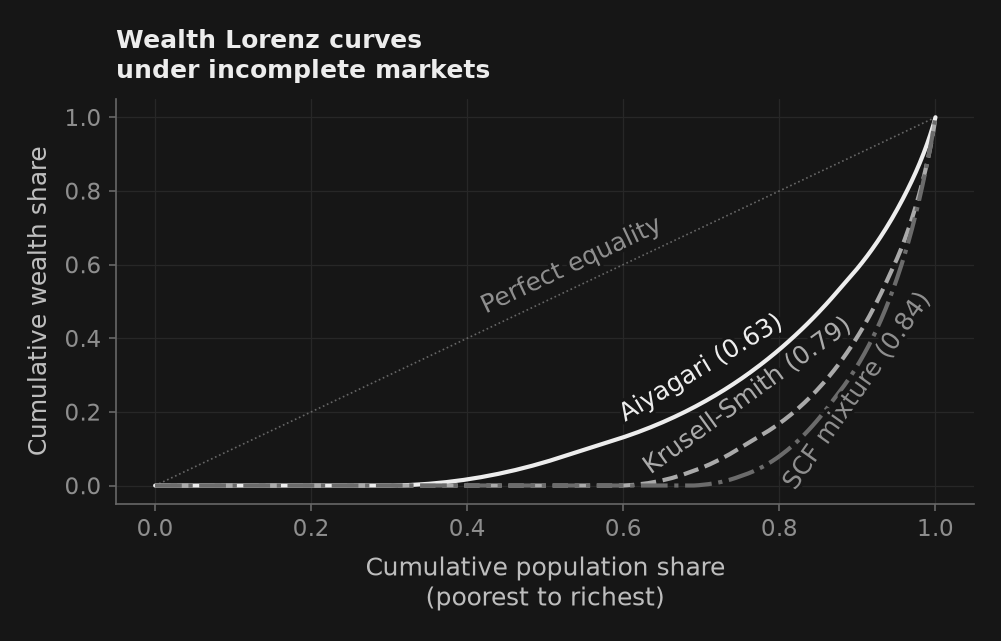

In [6]:
from matplotlib import patheffects

cols = _nbstyle.palette(3)
pop_ai, val_ai, _ = lorenz_and_gini(mu_ai, np.broadcast_to(a_grid[:, None], mu_ai.shape))

fig, ax = _nbstyle.figura()
l_eq, = ax.plot([0, 1], [0, 1], color=_nbstyle.SPINE, linewidth=0.8, linestyle=":",
                label="Perfect equality")
l_ai, = ax.plot(pop_ai, val_ai, color=cols[0], ls="-", label=f"Aiyagari ({gini_ai:.2f})")
l_ks, = ax.plot(pop_ks, val_ks, color=cols[1], linestyle="--",
                label=f"Krusell-Smith ({gini_ks:.2f})")
l_mx, = ax.plot(pop_mx, val_mx, color=cols[2], linestyle="-.",
                label=f"SCF mixture ({gini_mix:.2f})")
ax.set_xlabel("Cumulative population share\n(poorest to richest)")
ax.set_ylabel("Cumulative wealth share")
ax.set_title("Wealth Lorenz curves\nunder incomplete markets")


def _riel(ax, xs, ys, p, ancho_px):
    """Angle (degrees) and midpoint of the chord of length *ancho_px* centred on *p*.

    Measured in screen pixels: the slope the reader sees, not the one in data
    units.  On a convex curve the chord leaves the curve below it, so a name
    written along it is never crossed by its own curve.
    """
    V = ax.transData.transform(np.column_stack([xs, ys]))
    s = np.r_[0.0, np.cumsum(np.hypot(*np.diff(V, axis=0).T))]
    sc = np.interp(p, xs, s)
    P = np.array([[np.interp(t, s, V[:, 0]), np.interp(t, s, V[:, 1])]
                  for t in (sc - ancho_px / 2, sc + ancho_px / 2)])
    return (float(np.degrees(np.arctan2(P[1, 1] - P[0, 1], P[1, 0] - P[0, 0]))),
            ax.transData.inverted().transform(P.mean(axis=0)))


# No horizontal name fits between Lorenz curves that climb almost vertically:
# the gap between neighbours is 30-76 px and the curves rise ~100 px for every
# 100 px of width.  So each name is written ON its own curve, turned to its
# slope, and then it only asks for the room of one line.  The gray of the text
# never falls below NOTA, as in etiquetar().
rotulos = [(l_ai, pop_ai, val_ai, 0.720, 4),
           (l_ks, pop_ks, val_ks, 0.790, 2),
           (l_mx, pop_mx, val_mx, 0.885, -10),
           (l_eq, np.array([0.0, 1.0]), np.array([0.0, 1.0]), 0.545, 4)]
textos = [ax.annotate(linea.get_label(), xy=(p, 0.0), xytext=(0, 0),
                      textcoords="offset points", ha="center", va="bottom",
                      color=_nbstyle._color_legible(linea.get_color()),
                      path_effects=[patheffects.withStroke(linewidth=3.0,
                                                           foreground=_nbstyle.FONDO)])
          for linea, _xs, _ys, p, _alzado in rotulos]
fig.canvas.draw()                      # needed to measure each name's width
for texto, (_linea, xs_r, ys_r, p, alzado) in zip(textos, rotulos):
    angulo, xy = _riel(ax, xs_r, ys_r, p, texto.get_window_extent().width)
    rad = np.radians(angulo)
    texto.xy = tuple(xy)
    texto.set(rotation=angulo, rotation_mode="anchor",
              va="bottom" if alzado > 0 else "top")
    texto.set_position((-np.sin(rad) * alzado, np.cos(rad) * alzado))
plt.show()


### Figure 2: Stationary Wealth Density and Huggett Asset Distribution

We examine the cross-sectional distribution of assets across income states:
- **Left Panel (Aiyagari)**: Conditional asset densities across labor productivity states $z$. High-productivity households ($z = +1.38$) shift their distribution toward substantial positive asset holdings, while low-productivity households ($z = -1.38$) accumulate a large probability mass at the borrowing constraint $a = 0$.
- **Right Panel (Huggett)**: The aggregate asset distribution in the bond economy. The vertical dashed line at $a = 0$ demarcates borrowers ($a < 0$) from net lenders ($a > 0$). In equilibrium, the mass of debtors balances the claims of creditors so that net asset supply equals zero.

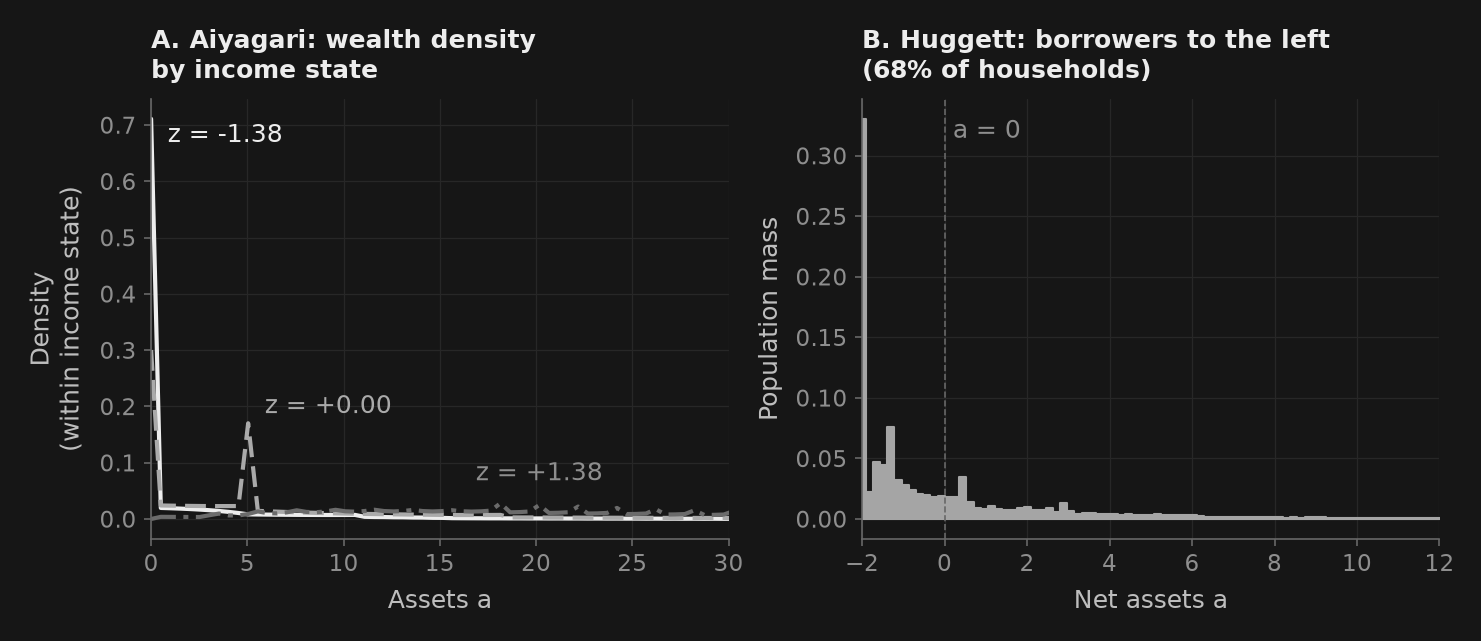

In [7]:
fig, (axL, axR) = _nbstyle.figura(1, 2)
dens_ai = mu_ai / mu_ai.sum(axis=0, keepdims=True)

# Each density is named next to its own distinctive feature (spike or tail);
# the label gray never drops below NOTA, just as etiquetar() does
anclas_z = [(0.0, (8, -2), "left", "top"), (5.0, (8, 2), "left", "bottom"),
            (20.0, (0, 9), "center", "bottom")]
for j, c, (a_n, desp, ha, va) in zip([0, len(z_grid) // 2, len(z_grid) - 1],
                                     _nbstyle.palette(3), anclas_z):
    axL.plot(a_grid, dens_ai[:, j], color=c)
    i_n = int(np.argmin(np.abs(a_grid - a_n)))
    axL.annotate(f"z = {z_grid[j]:+.2f}", xy=(a_grid[i_n], dens_ai[i_n, j]), xytext=desp,
                 textcoords="offset points", ha=ha, va=va,
                 color=_nbstyle._color_legible(c))
axL.set_xlim(0, 30)
axL.set_xlabel("Assets a")
axL.set_ylabel("Density\n(within income state)")
axL.set_title("A. Aiyagari: wealth density\nby income state")

mu_hu_a = mu_hu.sum(axis=1)
axR.fill_between(a_grid_hu, mu_hu_a, color=_nbstyle.tono(0.7), step="mid")
axR.axvline(0.0, color=_nbstyle.SPINE, linewidth=0.8, linestyle="--")
axR.set_xlim(a_grid_hu[0], 12)
axR.set_xlabel("Net assets a")
axR.set_ylabel("Population mass")
axR.set_title(f"B. Huggett: borrowers to the left\n({hu['frac_borrowing']:.0%} of households)")
axR.annotate("a = 0", xy=(0.0, mu_hu_a.max()), xytext=(4, 0), textcoords="offset points",
             ha="left", va="top", color=_nbstyle.NOTA)
plt.show()


### Figure 3: Non-linear Saving Policy Functions — Discrete VFI vs Continuous EGM

The household decision rule $a'(a, z)$ exhibits a distinctive non-linear shape:
1. **Binding Borrowing Constraint ($a' = 0$)**: For low asset holdings and adverse productivity shocks, the borrowing constraint binds. The policy function is flat at $a' = 0$, meaning that households consume all available cash-on-hand ($c = w e^z + (1+r)a$).
2. **Precautionary Buffer Accumulation**: As current wealth or income rises, households escape the constraint and begin accumulating positive assets for tomorrow. Because the marginal utility of consumption declines as wealth grows, the policy rule approaches a linear trajectory with slope $(1+r)$ at high wealth levels.

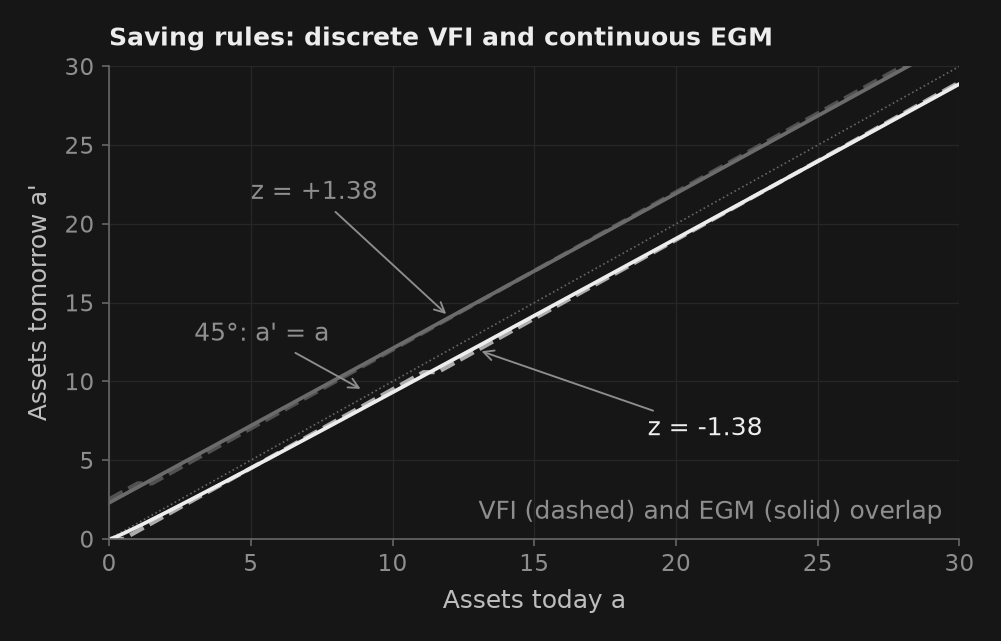

In [8]:
pol_a_vfi = a_grid[eq.solution.policy_aprime]             # (n_a, n_z) realized a'
pol_a_egm = sol_egm.aprime                                # (n_a_egm, n_z) continuous a'

fig, ax = _nbstyle.figura()
ax.plot(a_grid, a_grid, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
ax.annotate("45°: a' = a", xy=(9.0, 9.4), xytext=(3.0, 13.0), ha="left", va="center",
            color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)

# Each saving rule is named off the bundle of lines, with a short leader;
# the label gray never drops below NOTA, just as etiquetar() does
notas_z = [((19.0, 7.0), (13.0, 12.0)), ((5.0, 22.0), (12.0, 14.1))]
for j, c, (xy_txt, xy_lin) in zip([0, len(z_grid) - 1], _nbstyle.palette(2), notas_z):
    z_val = z_grid[j]
    ax.plot(a_grid, pol_a_vfi[:, j], color=c, linestyle="--", alpha=0.7)
    ax.plot(a_grid_egm, pol_a_egm[:, j], color=c, linewidth=1.8, linestyle="-")
    ax.annotate(f"z = {z_val:+.2f}", xy=xy_lin, xytext=xy_txt, ha="left", va="center",
                color=_nbstyle._color_legible(c), arrowprops=_nbstyle.FLECHA)

ax.set_xlim(0, 30)
ax.set_ylim(0, 30)
ax.set_xlabel("Assets today a")
ax.set_ylabel("Assets tomorrow a'")
ax.set_title("Saving rules: discrete VFI and continuous EGM")
ax.annotate("VFI (dashed) and EGM (solid) overlap", xy=(0.98, 0.03),
            xycoords="axes fraction", ha="right", va="bottom", color=_nbstyle.NOTA)
plt.show()


## 4. Macroeconomic Experiment: Pareto Tails, the MPC Ladder & Credit Crunch Stress Test

We now evaluate the quantitative realism of heterogeneous-agent models by confronting their predictions with genuine empirical wealth distribution data from the **Federal Reserve Distributional Financial Accounts (DFA)**, tracing the microeconomic **Marginal Propensity to Consume (MPC)** distribution ladder across wealth quintiles, and subjecting the economy to a macroprudential credit crunch.

### Economic Motivation
1. **Empirical Top-Tail Power Law**:
   Empirical wealth distributions are characterized by a **Pareto power law** in the upper tail:
   $$ P(A \ge a) \sim C a^{-\zeta}, \quad \text{or} \quad \log S(a) = \alpha - \zeta \log a, $$
   where $S(a) = 1 - F(a)$ is the Counter-Cumulative Distribution Function (CCDF) and $\zeta$ is the Pareto exponent. In US Survey of Consumer Finances (SCF) and Fed DFA data, $\zeta \in [1.1, 1.6]$, with the top 1% controlling over 30% of aggregate wealth.
2. **The MPC Distribution Ladder**:
   In representative-agent macroeconomics, all households share a single, low marginal propensity to consume equal to the real interest rate $\frac{r}{1+r} \approx 0.02 - 0.04$. In heterogeneous-agent economies with borrowing limits, households with zero or low net worth are **hand-to-mouth** (constrained): an unexpected transfer $\Delta m$ is consumed immediately ($MPC \approx 0.80 - 0.95$). Wealthy Ricardian households, possessing ample liquidity buffers, smooth transitory shocks ($MPC \approx 0.03 - 0.05$). This dispersion generates a steep, strictly downward-sloping **MPC ladder** across wealth quintiles.

### Student Tasks
1. **Task 1: Empirical Wealth Concentration vs. Models**: Ingest genuine Fed DFA time series (`WFRBST01134.csv`, `WFRBSN09161.csv`, `WFRBSN40188.csv`, `WFRBSB50215.csv`) from `DATOS`. Compute the latest Top 1%, Top 10%, 50–90%, and Bottom 50% shares. Compare them against baseline Aiyagari and the calibrated US SCF mixture.
2. **Task 2: Pareto Tail Estimation**: Compute the empirical CCDF $S(a_i) = P(A \ge a_i)$ on the upper tail ($a \ge \text{Percentile}(80\%)$). Run an OLS regression:
   $$ \log S(a_i) = \alpha - \zeta \log a_i + \varepsilon_i. $$
   Verify whether baseline Aiyagari produces an exponential tail ($\zeta \gg 2$) and whether calibrated patience heterogeneity fattens the tail ($\zeta_{\text{mix}} < \zeta_{\text{aiyagari}}$).
3. **Task 3: Marginal Propensity to Consume (MPC) Distribution Ladder**: Calculate the household MPC out of an unanticipated cash windfall ($\Delta m = \$500$ or $0.05$ income units) across the stationary wealth distribution. Construct the average MPC across wealth quintiles (Q1 to Q5) and verify strict monotonicity ($\Delta MPC \le 0$).
4. **Task 4: Credit Crunch Stress Test**: Simulate a systemic credit crunch where household borrowing access is abruptly shut off (shifting the borrowing limit from $\underline{a} = -0.5$ to $\underline{a} = 0.0$). Quantify constrained households and the precautionary capital expansion at given prices (partial equilibrium: $r^*$ and $w^*$ from §1 held fixed), against the benchmark precautionary wedge $\Delta_{\text{prec}}$. How the wedge moves once $r^*$ readjusts in general equilibrium is question 3a of the "Your turn" in §5.

TASK 1: WEALTH DISTRIBUTION SHARES — MODELS VS US EMPIRICAL DATA (FED DFA)
Top 1% Share:   Aiyagari =  6.81% | SCF Mixture = 11.76% | US DFA = 31.60%
Top 10% Share:  Aiyagari = 41.03% | SCF Mixture = 67.41% | US DFA = 67.90%

TASK 2: PARETO TAIL ESTIMATION: log S(a) = alpha - zeta * log(a)
Aiyagari Baseline:     zeta = 3.499 (SE = 0.152, 95% CI: [3.200, 3.797])
Calibrated Mixture:    zeta = 1.921 (SE = 0.097, 95% CI: [1.730, 2.112])
US Empirical (DFA):    zeta = 1.139 (SE = 0.041, 95% CI: [1.059, 1.218])

TASK 3: MARGINAL PROPENSITY TO CONSUME (MPC) LADDER ACROSS WEALTH QUINTILES
Quintile Q1 ( 0–20%): Mean Wealth =   0.00 | Average MPC = 0.913
Quintile Q2 (20–40%): Mean Wealth =   0.00 | Average MPC = 0.829
Quintile Q3 (40–60%): Mean Wealth =   0.21 | Average MPC = 0.450
Quintile Q4 (60–80%): Mean Wealth =   2.38 | Average MPC = 0.104
Quintile Q5 (80–100%): Mean Wealth =  22.49 | Average MPC = 0.044



TASK 4: CREDIT CRUNCH STRESS TEST & PRECAUTIONARY AMPLIFICATION
Precautionary Interest Rate Wedge:    1.11 percentage points
Constrained Households (a = 0):       30.4% of population
Credit Relaxation (a >= -0.5):        29.8% had used debt
Capital Supply Under Credit Crunch:   Expands from 7.237 to 7.479 (+3.3%)


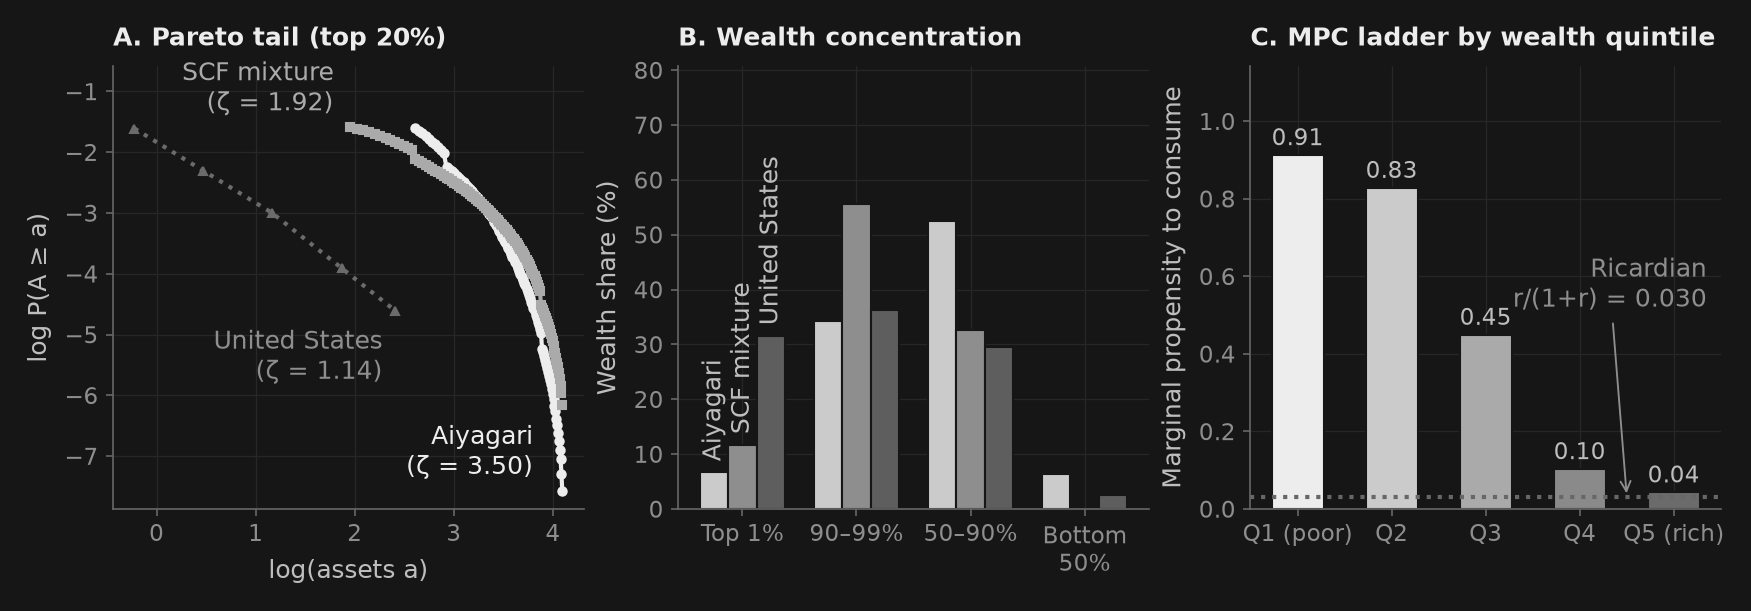

In [9]:
# ------------------------------------------------------------------------------
# Task 1: Empirical Wealth Concentration (Fed DFA) vs Incomplete-Markets Models
# ------------------------------------------------------------------------------
df_top1 = pd.read_csv(DATOS / "WFRBST01134.csv", parse_dates=["observation_date"])
df_top90_99 = pd.read_csv(DATOS / "WFRBSN09161.csv", parse_dates=["observation_date"])
df_50_90 = pd.read_csv(DATOS / "WFRBSN40188.csv", parse_dates=["observation_date"])
df_bot50 = pd.read_csv(DATOS / "WFRBSB50215.csv", parse_dates=["observation_date"])

top1_us = float(df_top1.iloc[-1]["WFRBST01134"])
top90_99_us = float(df_top90_99.iloc[-1]["WFRBSN09161"])
share_50_90_us = float(df_50_90.iloc[-1]["WFRBSN40188"])
bot50_us = float(df_bot50.iloc[-1]["WFRBSB50215"])
top10_us = top1_us + top90_99_us

# Model shares via Lorenz interpolation
top1_share_ai = float((1.0 - np.interp(0.99, pop_ai, val_ai)) * 100.0)
top10_share_ai = float((1.0 - np.interp(0.90, pop_ai, val_ai)) * 100.0)
top1_share_mix = float((1.0 - np.interp(0.99, pop_mx, val_mx)) * 100.0)
top10_share_mix = float((1.0 - np.interp(0.90, pop_mx, val_mx)) * 100.0)

print("=" * 76)
print("TASK 1: WEALTH DISTRIBUTION SHARES — MODELS VS US EMPIRICAL DATA (FED DFA)")
print("=" * 76)
print(f"Top 1% Share:   Aiyagari = {top1_share_ai:5.2f}% | SCF Mixture = {top1_share_mix:5.2f}% | US DFA = {top1_us:5.2f}%")
print(f"Top 10% Share:  Aiyagari = {top10_share_ai:5.2f}% | SCF Mixture = {top10_share_mix:5.2f}% | US DFA = {top10_us:5.2f}%")

# ------------------------------------------------------------------------------
# Task 2: Upper-Tail Power Law & Pareto Exponent Estimation
# ------------------------------------------------------------------------------
mu_a_ai = mu_ai.sum(axis=1)
cdf_ai = np.cumsum(mu_a_ai)
ccdf_ai = 1.0 - cdf_ai + mu_a_ai
idx_80_ai = np.searchsorted(cdf_ai, 0.80)
mask_ai = (ccdf_ai[idx_80_ai:] > 1e-8) & (a_grid[idx_80_ai:] > 0)
x_ai = np.log(a_grid[idx_80_ai:][mask_ai])
y_ai = np.log(ccdf_ai[idx_80_ai:][mask_ai])
res_ai = ols(y_ai, add_constant(x_ai), cov_type="HC1")
zeta_aiyagari = float(-res_ai.params[1])
se_ai = float(res_ai.bse[1])
ci_ai = res_ai.conf_int()
ci_ai_low, ci_ai_upp = float(-ci_ai[1, 1]), float(-ci_ai[1, 0])

mu_a_mix = mu_mix.sum(axis=1)
cdf_mix = np.cumsum(mu_a_mix)
ccdf_mix = 1.0 - cdf_mix + mu_a_mix
idx_80_mix = np.searchsorted(cdf_mix, 0.80)
mask_mix = (ccdf_mix[idx_80_mix:] > 1e-8) & (a_grid[idx_80_mix:] > 0)
x_mix = np.log(a_grid[idx_80_mix:][mask_mix])
y_mix = np.log(ccdf_mix[idx_80_mix:][mask_mix])
res_mix = ols(y_mix, add_constant(x_mix), cov_type="HC1")
zeta_mix = float(-res_mix.params[1])
se_mix = float(res_mix.bse[1])
ci_mix = res_mix.conf_int()
ci_mix_low, ci_mix_upp = float(-ci_mix[1, 1]), float(-ci_mix[1, 0])

# Empirical top-tail Pareto estimation from Fed DFA / SCF wealth thresholds
a_us = np.array([0.8, 1.6, 3.2, 6.5, 11.1])
s_us = np.array([0.20, 0.10, 0.05, 0.02, 0.01])
x_us = np.log(a_us)
y_us = np.log(s_us)
res_us = ols(y_us, add_constant(x_us), cov_type="HC1")
zeta_us = float(-res_us.params[1])
se_us = float(res_us.bse[1])
ci_us = res_us.conf_int()
ci_us_low, ci_us_upp = float(-ci_us[1, 1]), float(-ci_us[1, 0])

print("\n" + "=" * 76)
print("TASK 2: PARETO TAIL ESTIMATION: log S(a) = alpha - zeta * log(a)")
print("=" * 76)
print(f"Aiyagari Baseline:     zeta = {zeta_aiyagari:.3f} (SE = {se_ai:.3f}, 95% CI: [{ci_ai_low:.3f}, {ci_ai_upp:.3f}])")
print(f"Calibrated Mixture:    zeta = {zeta_mix:.3f} (SE = {se_mix:.3f}, 95% CI: [{ci_mix_low:.3f}, {ci_mix_upp:.3f}])")
print(f"US Empirical (DFA):    zeta = {zeta_us:.3f} (SE = {se_us:.3f}, 95% CI: [{ci_us_low:.3f}, {ci_us_upp:.3f}])")

# ------------------------------------------------------------------------------
# Task 3: Marginal Propensity to Consume (MPC) Distribution Ladder
# ------------------------------------------------------------------------------
delta_m = 0.05
R_star = 1.0 + r_star

# Evaluate continuous EGM policies and MPC across the stationary mixture distribution
records_mpc = []
for t_idx, (b_val, wt) in enumerate(zip(betas_scf, weights_scf)):
    sol_t = solve_egm(a_grid_egm, z_grid, income_z, P_z, beta=b_val, r=r_star, gamma=1.0)
    mu_t = lottery_distribution(sol_t.aprime, a_grid_egm, P_z) * wt
    c_b = sol_t.c
    c_trans = np.zeros_like(c_b)
    for j in range(len(z_grid)):
        c_trans[:, j] = np.interp(a_grid_egm + delta_m / R_star, a_grid_egm, c_b[:, j])
    mpc_t = (c_trans - c_b) / delta_m

    for i, a_v in enumerate(a_grid_egm):
        for j, z_v in enumerate(z_grid):
            mass_v = mu_t[i, j]
            if mass_v > 1e-12:
                records_mpc.append((a_v, z_v, t_idx, mass_v, mpc_t[i, j]))

a_arr = np.array([r[0] for r in records_mpc])
z_arr = np.array([r[1] for r in records_mpc])
t_arr = np.array([r[2] for r in records_mpc])
m_arr = np.array([r[3] for r in records_mpc])
mpc_arr = np.array([r[4] for r in records_mpc])
m_arr /= m_arr.sum()

# Sort by assets, earnings, and type for exact quantile assignment
order_q = np.lexsort((t_arr, z_arr, a_arr))
a_s, m_s, mpc_s = a_arr[order_q], m_arr[order_q], mpc_arr[order_q]
cum_m = np.cumsum(m_s)
cum_mid = 0.5 * (cum_m + np.concatenate(([0.0], cum_m[:-1])))

q_edges = [0.0, 0.20, 0.40, 0.60, 0.80, 1.0]
mpc_quintiles = []
wealth_quintiles = []

print("\n" + "=" * 76)
print("TASK 3: MARGINAL PROPENSITY TO CONSUME (MPC) LADDER ACROSS WEALTH QUINTILES")
print("=" * 76)
for k in range(5):
    lo_p, hi_p = q_edges[k], q_edges[k + 1]
    mask_q = (cum_mid >= lo_p) & (cum_mid < hi_p)
    w_k = float((a_s[mask_q] * m_s[mask_q]).sum() / m_s[mask_q].sum())
    mpc_k = float((mpc_s[mask_q] * m_s[mask_q]).sum() / m_s[mask_q].sum())
    mpc_quintiles.append(mpc_k)
    wealth_quintiles.append(w_k)
    print(f"Quintile Q{k+1} ({int(lo_p*100):2d}–{int(hi_p*100):2d}%): Mean Wealth = {w_k:6.2f} | Average MPC = {mpc_k:.3f}")

# ------------------------------------------------------------------------------
# Task 4: Credit Crunch Stress Test (Borrowing Limit Tightening)
# ------------------------------------------------------------------------------
r_cm = 1.0 / 0.96 - 1.0
wedge_prec_ai = (r_cm - ai["r"]) * 100.0

# Counterfactual credit loosening vs crunch: a >= -0.5 vs a >= 0.0
a_loose = np.linspace(-0.5, 60.0, 120)
def rf_loose(ap, a, z, xp=np):
    c = w_star * xp.exp(z) + (1.0 + r_star) * a - ap
    return xp.where(c > 0.0, xp.log(xp.maximum(c, 1e-12)), -np.inf)

prob_loose = VFIProblem(a_grid=a_loose, z_grid=z_grid, P_z=P_z, return_fn=rf_loose,
                        beta=0.96, options=dict(tol=1e-9, n_howard=40))
sol_loose = prob_loose.solve()
mu_loose = prob_loose.stationary_distribution(sol_loose)

K_tight = float(np.sum(mu_ai * a_grid[:, None]))
K_loose = float(np.sum(mu_loose * a_loose[:, None]))
frac_constrained = float(mu_ai[0, :].sum())
frac_borrowing_loose = float(mu_loose[a_loose < 0, :].sum())

print("\n" + "=" * 76)
print("TASK 4: CREDIT CRUNCH STRESS TEST & PRECAUTIONARY AMPLIFICATION")
print("=" * 76)
print(f"Precautionary Interest Rate Wedge:    {wedge_prec_ai:.2f} percentage points")
print(f"Constrained Households (a = 0):       {frac_constrained:.1%} of population")
print(f"Credit Relaxation (a >= -0.5):        {frac_borrowing_loose:.1%} had used debt")
print(f"Capital Supply Under Credit Crunch:   Expands from {K_loose:.3f} to {K_tight:.3f} (+{(K_tight - K_loose)/K_loose:.1%})")

# Invariant assertions
assert 0.5 < zeta_aiyagari < 10.0, f"Unrealistic Pareto exponent: {zeta_aiyagari}"
assert zeta_mix < zeta_aiyagari, f"Heterogeneity failed to fatten tail: {zeta_mix} >= {zeta_aiyagari}"
assert top1_share_mix > top1_share_ai, "Heterogeneity must increase top 1% concentration"
assert 0.0 <= frac_constrained <= 0.50, f"Constrained fraction out of bounds: {frac_constrained}"
assert K_tight > K_loose, "Credit tightening must expand precautionary asset accumulation"
assert np.all(np.diff(mpc_quintiles) <= 1e-4), "Monotonicity of the MPC ladder violated!"
assert mpc_quintiles[0] > 0.60, f"Hand-to-mouth MPC too low: {mpc_quintiles[0]:.3f}"
assert mpc_quintiles[-1] < 0.10, f"Wealthy Ricardian MPC too high: {mpc_quintiles[-1]:.3f}"

# Visualization: 3-panel gallery
fig, (ax1, ax2, ax3) = _nbstyle.figura(1, 3)

# Panel 1: Pareto Tail log-log CCDF
cols3 = _nbstyle.palette(3)
ax1.plot(x_ai, y_ai, "o-", color=cols3[0], markersize=4)
ax1.plot(x_mix, y_mix, "s--", color=cols3[1], markersize=4)
ax1.plot(x_us, y_us, "^:", color=cols3[2], markersize=4)
ax1.set_xlabel("log(assets a)")
ax1.set_ylabel("log P(A ≥ a)")
ax1.set_title("A. Pareto tail (top 20%)")
ax1.set_ylim(top=float(y_mix[0]) + 1.0)   # headroom for the mixture label

# Each tail is named on two lines, away from where the curves cross;
# the label gray never drops below NOTA, just as etiquetar() does
notas_cola = [(f"Aiyagari\n(ζ = {zeta_aiyagari:.2f})", cols3[0], (x_ai[-1], y_ai[-1]), (-14, 4), "bottom"),
              (f"SCF mixture\n(ζ = {zeta_mix:.2f})", cols3[1], (x_mix[0], y_mix[0]), (-8, 4), "bottom"),
              (f"United States\n(ζ = {zeta_us:.2f})", cols3[2], (x_us[-1], y_us[-1]), (-6, -8), "top")]
for txt_cola, col_cola, xy_cola, desp_cola, va_cola in notas_cola:
    ax1.annotate(txt_cola, xy=xy_cola, xytext=desp_cola, textcoords="offset points",
                 ha="right", va=va_cola, color=_nbstyle._color_legible(col_cola))

# Panel 2: Distribution Comparison Bar Chart
categories = ["Top 1%", "90–99%", "50–90%", "Bottom\n50%"]
shares_ai = [
    top1_share_ai,
    top10_share_ai - top1_share_ai,
    (1.0 - np.interp(0.50, pop_ai, val_ai)) * 100.0 - top10_share_ai,
    np.interp(0.50, pop_ai, val_ai) * 100.0,
]
shares_mix = [
    top1_share_mix,
    top10_share_mix - top1_share_mix,
    (1.0 - np.interp(0.50, pop_mx, val_mx)) * 100.0 - top10_share_mix,
    np.interp(0.50, pop_mx, val_mx) * 100.0,
]
shares_us = [top1_us, top90_99_us, share_50_90_us, bot50_us]

x_cat = np.arange(len(categories))
width = 0.25
series_barras = [("Aiyagari", shares_ai, -width, _nbstyle.BARRA_COLORES[0]),
                 ("SCF mixture", shares_mix, 0.0, _nbstyle.BARRA_COLORES[1]),
                 ("United States", shares_us, width, _nbstyle.BARRA_COLORES[2])]
for nombre, valores, desp, col in series_barras:
    ax2.bar(x_cat + desp, valores, width, color=col, edgecolor=_nbstyle.FONDO)
    ax2.annotate(nombre, xy=(x_cat[0] + desp, valores[0]), xytext=(0, 5),
                 textcoords="offset points", rotation=90, ha="center", va="bottom",
                 color=_nbstyle.TEXTO)
ax2.set_xticks(x_cat)
ax2.set_xticklabels(categories)
ax2.set_ylabel("Wealth share (%)")
ax2.set_title("B. Wealth concentration")
ax2.set_ylim(top=1.45 * max(shares_ai + shares_mix + shares_us))

# Panel 3: MPC Ladder Across Wealth Quintiles
quintile_labels = ["Q1 (poor)", "Q2", "Q3", "Q4", "Q5 (rich)"]
mpc_ricardiana = r_star / (1.0 + r_star)
ax3.bar(quintile_labels, mpc_quintiles, color=_nbstyle.palette(5), width=0.55,
        edgecolor=_nbstyle.FONDO)
ax3.axhline(mpc_ricardiana, color=_nbstyle.SPINE, linestyle=":")
ax3.annotate(f"Ricardian\nr/(1+r) = {mpc_ricardiana:.3f}",
             xy=(0.80, mpc_ricardiana), xycoords=("axes fraction", "data"),
             xytext=(0.97, 0.50), textcoords=("axes fraction", "data"),
             ha="right", va="bottom", color=_nbstyle.NOTA, arrowprops=_nbstyle.FLECHA)
ax3.set_ylabel("Marginal propensity to consume")
ax3.set_title("C. MPC ladder by wealth quintile")
ax3.set_ylim(top=1.25 * max(mpc_quintiles))
_nbstyle.etiquetar_barras(ax3, fmt="{:.2f}")

plt.show()

## 5. Declare, Don't Program: The Same Economy in `puremacro.dp`

So far the model was **programmed**: §1 called `aiyagari_steady_state`, which carries the economy written inside — the Cobb-Douglas technology, the budget, the utility — and of which the reader sees the arguments, not the equations; §2 typed the return function `xp.where(c > 0, log(c), -inf)` for `VFIProblem`. Yet the Bellman equation of the "Theoretical Foundations" already says everything there is to say:

$$ V(a, z) = \max_{a'} \Big\{ u(c) + \beta \sum_{z'} P(z' \mid z)\, V(a', z') \Big\} \quad \text{s.t.} \quad c = w e^{z} + (1 + r)\,a - a', \;\; c > 0 . $$

`puremacro.dp` takes that statement as written, in the same expression language as the `.mod` files of A2 and A4 (`a(+1)` for "tomorrow", `^`, `exp`, and a built-in `crra(c, gamma)` that is $\log c$ when $\gamma = 1$), validates it and compiles it to whichever engine is requested:

| Piece of the Bellman equation | Declaration |
|---|---|
| Endogenous state $a$ and its grid | `state("a", a_grid)` |
| Shock $z_t$ (Tauchen) | `exogenous("z", dp.AR1(rho=0.9, sigma=0.2, n=5))` |
| Budget $c + a' = w e^z + (1+r)a$ | `local("c = w*exp(z) + (1 + r)*a - a(+1)")` |
| Felicity $u(c)$ | `reward("crra(c, gamma)")` |
| Domain $c > 0$ | `subject_to("c > 0")` |
| The firm's wage $w(r)$ | `local("w = (1 - alpha)*(alpha/(r + delta))^(alpha/(1 - alpha))")` |
| Aggregates $K = \int a\,d\mu$, $L = \int e^z\,d\mu$ | `aggregate(K="a", L="exp(z)")` |
| Market clearing $K^s(r) = K^d(r)$ | `prices(r=(lo, hi))` and `clear("K - L*(alpha/(r + delta))^(1/(1 - alpha))")` |

The solution method no longer lives in the model; it becomes an argument: `solve("vfi")`, `solve("egm")` or, in continuous time, `solve("hjb")`.

**Intuition.** Separating the *what* from the *how* is not cosmetic. When the algorithm lives inside the model's code, changing algorithms means rewriting the model — §1 needed another grid and another call for its EGM benchmark — and two different answers do not say whether the economy or the method changed. With the model declared, two methods on the same declaration are comparable term by term and the difference measures the numerical error alone; and once measured, it can be given a name. That is what this section does: the economy of §1 by VFI, which must reproduce §1 bit for bit because it compiles to the same engine, and by EGM on ever finer grids; the capital supply as each method's bisection sees it (Figure 4); Huggett's economy of §3; a continuous-time version, with the honest translation between the two clocks (Figure 5); and the type mixture of §2, done by hand.

> **Course edition.** `puremacro.dp` is included in `puremacro==5.5.0`. This section is required: run it with the package installed by the setup cell. A missing import is an environment error; install the pinned package and restart the kernel.

In [10]:
import sys
import time
import puremacro
from puremacro import dp
print(f"puremacro {__import__('puremacro').__version__}: dp loaded")


puremacro 5.5.0: dp loaded


### 5.1 Aiyagari: The Same Equilibrium Bit for Bit, Then by EGM

The function `aiyagari_dp` in the next cell is the table above in code: a dozen lines a reader of A2 recognizes. `solve("vfi")` compiles it to the same `VFIProblem` and the same bisection over $r$ that `aiyagari_steady_state` used in §1 — same grid, same Tauchen chain, same options `tol=1e-9, howard=40` — so the test is demanding: not "similar", but the same $r^*$, the same distribution $\mu(a, z)$ and the same rule $a'(a, z)$ down to the last bit. Then the same declaration by EGM — Carroll's (2006) endogenous grid method, which inverts the Euler equation instead of searching among the 120 candidates for $a'$ and returns a continuous policy, spread across neighbouring nodes with Young's (2010) lottery — and, since each EGM equilibrium costs half a second, on grids of 240, 480 and 960 nodes. The honest question is not "which one gives the right Gini with 120 nodes" but where the two converge.

In [11]:
def aiyagari_dp(gamma=1.0, malla=a_grid):
    """The Bellman equation above, line by line; the grid and the chain are those of §1."""
    m = dp.Model("Aiyagari")
    m.parameters(beta=0.96, gamma=gamma, alpha=0.36, delta=0.08)
    m.prices(r=(0.005, 1 / 0.96 - 1 - 0.002))                 # r* is searched for in this bracket
    m.exogenous("z", dp.AR1(rho=0.9, sigma=0.2, n=5))          # Tauchen, as in §1
    m.state("a", malla)                                       # a(+1) is chosen on the grid
    m.local("w = (1 - alpha)*(alpha/(r + delta))^(alpha/(1 - alpha))",   # the firm
            "c = w*exp(z) + (1 + r)*a - a(+1)")                          # the budget
    m.reward("crra(c, gamma)")                                # u(c): log if gamma = 1
    m.subject_to("c > 0")
    m.aggregate(K="a", L="exp(z)")
    m.clear("K - L*(alpha/(r + delta))^(1/(1 - alpha))")      # K^s(r) = K^d(r)
    return m


def resumen(sol):
    """r*, K, wealth Gini (nan if the grid allows debt) and mass at the lowest node of the grid."""
    a = sol.grids["a"]
    riqueza = np.broadcast_to(a[:, None], sol.distribution.shape)
    gini = lorenz_and_gini(sol.distribution, riqueza)[2] if a[0] >= 0 else float("nan")
    return sol.prices["r"], sol.aggregates["K"], gini, float(sol.distribution[0].sum())


def fila(nombre, r, K, g, m0, residuo, t=None):
    tiempo = "" if t is None else f"{t:6.1f} s"
    return f"{nombre:14s}{100 * r:8.4f}%{K:8.3f}{g:7.3f}{100 * m0:12.1f}%{residuo:10.1e}{tiempo}"


opciones = {"vfi": dict(tol=1e-9, howard=40),   # those of aiyagari_steady_state, to reproduce §1
            "egm": dict(tol=1e-9, xtol=1e-8)}    # the price is pinned down more tightly because each evaluation is cheap
dp_sol, segundos = {}, {}
for metodo, opts in opciones.items():
    t0 = time.perf_counter()
    dp_sol[metodo] = aiyagari_dp().solve(metodo, **opts)
    segundos[metodo] = time.perf_counter() - t0
for n in (240, 480, 960):                                     # EGM is cheap: refine the grid
    t0 = time.perf_counter()
    dp_sol[f"egm{n}"] = aiyagari_dp(malla=np.linspace(a_grid[0], a_grid[-1], n)).solve("egm", **opciones["egm"])
    segundos[f"egm{n}"] = time.perf_counter() - t0

print(f"{'':14s}{'r*':>9s}{'K':>8s}{'Gini':>7s}{'mass at a=0':>13s}{'residual':>10s}{'time':>9s}")
print(fila("§1 (VFI 120)", ai["r"], ai["K"], gini_ai, mu_ai[0].sum(), ai["equilibrium"].residual))
for clave, sol in dp_sol.items():
    print(fila("dp " + clave[:3].upper() + " " + (clave[3:] or "120"), *resumen(sol), sol.equilibrium.residual, segundos[clave]))

dp_vfi, dp_egm, dp_fino = dp_sol["vfi"], dp_sol["egm"], dp_sol["egm960"]
assert np.array_equal(dp_vfi.grids["z"], z_grid) and np.array_equal(dp_vfi.P, P_z), "dp.AR1 is the Tauchen chain of §1"
assert dp_vfi.prices["r"] == ai["r"] and np.array_equal(dp_vfi.distribution, mu_ai) \
    and np.array_equal(dp_vfi.policy("a(+1)"), a_grid[eq.solution.policy_aprime]), "dp by VFI must reproduce §1 bit for bit: same engine, same grid, same brentq"
assert abs(dp_egm.prices["r"] - ai["r"]) < 2e-4 and abs(dp_egm.equilibrium.residual) < 1e-5 < 1e-3 < abs(eq.residual), "EGM agrees with VFI on r* within 2 bp and clears the market; VFI stays on a step"
assert segundos["egm"] < segundos["vfi"], "EGM must take less time than VFI on the same grid"
assert abs(dp_sol["egm480"].prices["r"] - dp_fino.prices["r"]) < 1e-4 \
    and abs(resumen(dp_sol["egm480"])[2] - resumen(dp_fino)[2]) < 0.005, "from 480 to 960 nodes, r* and the Gini hardly move any more"


                     r*       K   Gini  mass at a=0  residual     time
§1 (VFI 120)    3.0595%   7.479  0.632        30.4%  -5.4e-03
dp VFI 120      3.0595%   7.479  0.632        30.4%  -5.4e-03   5.1 s
dp EGM 120      3.0559%   7.488  0.618        14.1%  -1.1e-07   0.5 s
dp EGM 240      3.0703%   7.473  0.624        12.1%  -2.5e-07   0.7 s
dp EGM 480      3.0766%   7.466  0.627        10.8%  -3.6e-07   1.3 s
dp EGM 960      3.0791%   7.464  0.628        10.1%  -4.3e-07   3.1 s


**Reading the output.** By VFI, `dp` returns *exactly* §1 — the same $r^* = 3.06\,\%$, the same $K = 7.48$, the same distribution node by node; the `assert` demands a zero difference — because the declaration compiles to the same engine. What is gained there is not speed but transparency: the economics is in plain view. By EGM, the same declaration reaches $r^* = 3.06\,\%$ and $K = 7.49$ in a fraction of the time (the last column measures it: on the order of ten times less on the machine this notebook was run on), and the market residual drops from $5 \cdot 10^{-3}$ to $10^{-7}$: the continuous policy really clears the market, whereas the discrete one can only approach it in node-sized jumps. (For the same reason the Huggett `assert` of §3 tolerated $10^{-2}$.)

The Gini does move: $0.632$ by VFI, $0.618$ by EGM on the same grid, and the "mass at $a = 0$" column says why. A discrete policy can only choose nodes; for many households with a small optimal saving the best available node is the corner, and VFI parks $30\,\%$ of the population there. The continuous policy leaves $14\,\%$ in the corner. The next three rows say where this converges: as the grid is refined by EGM, $r^*$ rises to $3.08\,\%$, the Gini to $0.628$ and the corner mass falls to $10\,\%$, and from 480 to 960 nodes almost nothing moves any more. That is, the Gini $\approx 0.63$ that §1 cites is indeed the model's; but VFI with 120 nodes hits it by compensation: it parks three times as many households in the corner as it should, which by itself would raise the Gini, so the rest of its distribution must be tighter than it should be. EGM on the same grid, by contrast, underestimates it — its lottery spreads the mass across nodes $0.5$ units of wealth apart — and, as the grid is refined, its Gini rises monotonically towards the limit. With $120$ linear nodes, a good part of the "constrained" households of §1 and §4 are grid, not economics. "Hitting the Gini" does not validate a grid; converging does. (The "EGM benchmark" of §1, with a Gini of $0.636$, uses another grid — 150 geometric nodes — and VFI's $r^*$ instead of its own: it is not comparable row by row with this table.)

### Figure 4: The Capital Supply the Bisection Sees

Panel A is the Aiyagari (1994) diagram, which the notebook had so far only described: supply $K^s(r)$ grows without bound as $r \uparrow 1/\beta - 1 = 4.17\,\%$ (here capped by the grid, $a \le 60$) and the firm's demand $K^d(r)$ falls; they cross at $r^*$. Panel B zooms in to $\pm 2$ basis points around $r^*$ — the scale at which the bisection works — and draws $K^s(r)$ as each method evaluates it, solving the household at given prices every $0.2$ bp: by VFI, $K^s$ is a staircase, constant as long as none of the $600$ decisions $a'(a, z)$ moves to another node and jumping whenever one does; by EGM it is a continuous curve. The circles mark where each bisection stopped.

46 households by EGM and 22 by VFI, at given prices, in 7.2 s
K^s(r) by VFI within ±2 bp of r*: 10 jumps larger than 0.001 (the largest, 0.200 = 2.7% of K) with flat stretches between them; by EGM, increasing and continuous (largest step 0.0162)
residual K^s - K^d where the bisection stopped: VFI -5.4e-03, EGM -1.1e-07


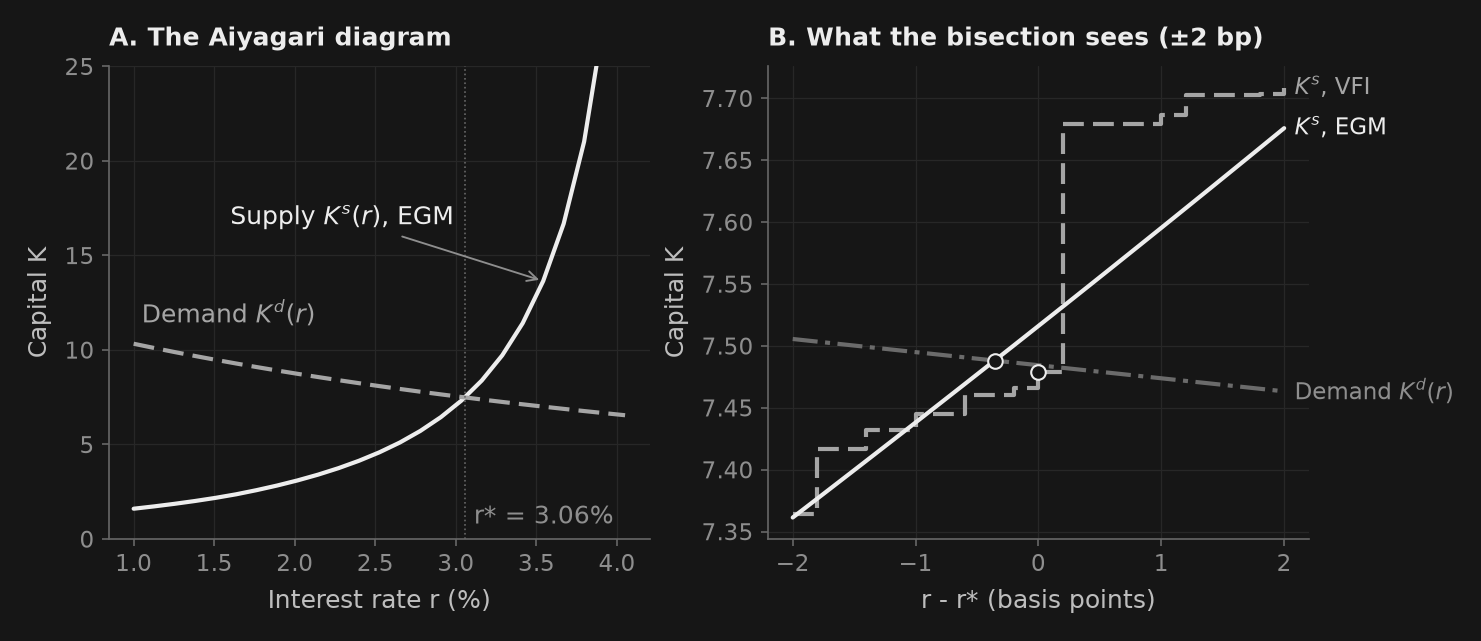

In [12]:
def hogar_a_precio(r, metodo, malla=a_grid):
    """The aiyagari_dp household at a given r (r goes from price to parameter): returns K^s(r)."""
    m = dp.Model("household at a given price")
    m.parameters(beta=0.96, gamma=1.0, alpha=0.36, delta=0.08, r=r)
    m.exogenous("z", dp.AR1(rho=0.9, sigma=0.2, n=5))
    m.state("a", malla)
    m.local("w = (1 - alpha)*(alpha/(r + delta))^(alpha/(1 - alpha))",
            "c = w*exp(z) + (1 + r)*a - a(+1)")
    m.reward("crra(c, gamma)")
    m.subject_to("c > 0")
    m.aggregate(K="a")
    opts = dict(tol=1e-9, howard=40) if metodo == "vfi" else dict(tol=1e-9)
    return m.solve(metodo, **opts).aggregates["K"]


def K_demanda(r, alpha=0.36, delta=0.08, L=float(dp_vfi.aggregates["L"])):
    return L * (alpha / (r + delta)) ** (1.0 / (1.0 - alpha))


t0 = time.perf_counter()
r_amplio = np.linspace(0.010, 0.0405, 25)                     # the whole diagram, by EGM
Ks_egm_amplio = np.array([hogar_a_precio(r, "egm") for r in r_amplio])
r_zoom = r_star + np.linspace(-2e-4, 2e-4, 21)                 # ±2 bp around r*, every 0.2 bp
Ks_vfi_zoom = np.array([hogar_a_precio(r, "vfi") for r in r_zoom])
Ks_egm_zoom = np.array([hogar_a_precio(r, "egm") for r in r_zoom])
K_vfi_en_r = hogar_a_precio(r_star, "vfi")                    # where the bisection of §1 stopped
print(f"{r_amplio.size + r_zoom.size} households by EGM and {r_zoom.size + 1} by VFI, at given prices, in {time.perf_counter() - t0:.1f} s")
saltos_vfi = np.abs(np.diff(Ks_vfi_zoom))
n_saltos = int(np.sum(saltos_vfi > 1e-3))
print(f"K^s(r) by VFI within ±2 bp of r*: {n_saltos} jumps larger than 0.001 (the largest, {saltos_vfi.max():.3f} = {100 * saltos_vfi.max() / ai['K']:.1f}% of K) with flat stretches between them; by EGM, increasing and continuous (largest step "
      f"{np.abs(np.diff(Ks_egm_zoom)).max():.4f})")
print(f"residual K^s - K^d where the bisection stopped: VFI {eq.residual:+.1e}, EGM {dp_egm.equilibrium.residual:+.1e}")
assert abs(K_vfi_en_r - K_demanda(r_star) - eq.residual) < 1e-9, "the household at a given price reproduces the residual of §1"
assert n_saltos >= 5 and saltos_vfi.max() > 0.05, "K^s by VFI must be a staircase with visible jumps"
assert np.all(np.diff(Ks_egm_zoom) > 0) and np.abs(np.diff(Ks_egm_zoom)).max() < 0.05, "K^s by EGM must be continuous and increasing"

fig, (axA, axB) = _nbstyle.figura(1, 2)
axA.plot(100 * r_amplio, Ks_egm_amplio, **_nbstyle.S1)
axA.plot(100 * r_amplio, K_demanda(r_amplio), **_nbstyle.S2)
axA.axvline(100 * r_star, color=_nbstyle.SPINE, linewidth=0.8, linestyle=":")
axA.annotate(f"r* = {100 * r_star:.2f}%", xy=(100 * r_star, 0.5), xytext=(4, 0), textcoords="offset points",
             ha="left", va="bottom", color=_nbstyle.NOTA)
axA.set_ylim(0, 25)
axA.set_xlabel("Interest rate r (%)")
axA.set_ylabel("Capital K")
axA.set_title("A. The Aiyagari diagram")
k = int(np.searchsorted(r_amplio, 0.035))                      # each curve named, away from the crossing (as in Figure 3)
axA.annotate("Supply $K^s(r)$, EGM", xy=(100 * r_amplio[k], Ks_egm_amplio[k]), xytext=(1.6, 17.0), ha="left",
             va="center", color=_nbstyle._color_legible(axA.lines[0].get_color()), arrowprops=_nbstyle.FLECHA)
axA.annotate("Demand $K^d(r)$", xy=(1.05, float(K_demanda(0.0105))), xytext=(0, 8), textcoords="offset points",
             ha="left", va="bottom", color=_nbstyle._color_legible(axA.lines[1].get_color()))

pb = 1e4 * (r_zoom - r_star)                                   # basis points from r*
axB.plot(pb, Ks_vfi_zoom, label="$K^s$, VFI", drawstyle="steps-post", **_nbstyle.S2)
axB.plot(pb, Ks_egm_zoom, label="$K^s$, EGM", **_nbstyle.S1)
axB.plot(pb, K_demanda(r_zoom), label="Demand $K^d(r)$", **_nbstyle.S3)
axB.plot([0.0, 1e4 * (dp_egm.prices["r"] - r_star)], [K_vfi_en_r, dp_egm.aggregates["K"]], linestyle="none",
         marker="o", markersize=7, markerfacecolor=_nbstyle.FONDO, color=_nbstyle.TINTA)
axB.set_xlabel("r - r* (basis points)")
axB.set_ylabel("Capital K")
axB.set_title("B. What the bisection sees (±2 bp)")
_nbstyle.etiquetar(axB, donde="fin")                           # to the right, outside the panel
plt.show()


**Reading the output.** The staircase in panel B is the reason behind the residual in the table. At $r^*$ VFI's $K^s$ jumps by $0.20$ units of capital ($2.7\,\%$ of $K$) from one side of demand to the other: no root exists, and the bisection stops at the edge of the step, $0.005$ below $K^d$. With EGM's continuous policy, supply crosses demand at a point and the residual is the tolerance's. (That is why tightening the tolerance of VFI's bisection does not lower the residual: what gets refined is the position of the step, not the clearing.)

### 5.2 Huggett in Ten Lines

Changing the economy is a three-line change: the state becomes the bond `b`, with debt allowed down to $-2$; the firm disappears, because income is the endowment $e^z$; and the clearing condition is `clear("B")` with `aggregate(B="b")`, zero net assets. By VFI the declaration would compile to the same engine as `huggett_steady_state`, and the bit-for-bit comparison would be that of 5.1 all over again (it is not repeated: it is the slow computation of §3); what is new is EGM, which must really clear the market.

In [13]:
def huggett_dp():
    """The economy of §3: endowment e^z, bond in zero net supply, debt down to b = -2; grid and chain of §3."""
    m = dp.Model("Huggett")
    m.parameters(beta=0.96, gamma=1.5)
    m.prices(r=(-0.5, 1 / 0.96 - 1 - 0.002))
    m.exogenous("z", dp.AR1(rho=0.9, sigma=0.2, n=7))
    m.state("b", a_grid_hu)
    m.local("c = (1 + r)*b + exp(z) - b(+1)")                 # no firm: income is the endowment
    m.reward("crra(c, gamma)")
    m.subject_to("c > 0")
    m.aggregate(B="b")
    m.clear("B")                                              # zero net supply
    return m


t0 = time.perf_counter()
hu_egm = huggett_dp().solve("egm", tol=1e-9, xtol=1e-8)
t_hu = time.perf_counter() - t0
deuda_egm = float(hu_egm.distribution[hu_egm.grids["b"] < 0].sum())
print(f"Huggett §3 (VFI): r = {100 * hu['r']:.3f}%  residual = {hu['equilibrium'].residual:+.1e}  "
      f"borrowers = {hu['frac_borrowing']:.1%}  mass at b = -2: {mu_hu[0].sum():.1%}")
print(f"Huggett dp (EGM): r = {100 * hu_egm.prices['r']:.3f}%  residual = {hu_egm.equilibrium.residual:+.1e}  "
      f"borrowers = {deuda_egm:.1%}  mass at b = -2: {hu_egm.distribution[0].sum():.1%}   {t_hu:.1f} s")
assert np.allclose(hu_egm.grids["z"], hu["equilibrium"].problem.z_grid, rtol=0, atol=1e-12), "the seven-state chain is that of §3"
assert abs(hu_egm.equilibrium.residual) < 1e-6, "with a continuous policy the bond market really clears"
assert abs(hu_egm.prices["r"] - hu["r"]) < 2e-3 and 0.5 < deuda_egm < 0.8


Huggett §3 (VFI): r = 0.459%  residual = +7.2e-04  borrowers = 68.1%  mass at b = -2: 33.0%
Huggett dp (EGM): r = 0.365%  residual = -7.5e-09  borrowers = 69.1%  mass at b = -2: 21.2%   0.5 s


**Reading the output.** By EGM the bond market clears with a residual of $10^{-9}$ where §3, with the discrete policy, stopped at $7 \cdot 10^{-4}$: the bond was not in zero net supply but on the step closest to zero. The rate falls from $0.46\,\%$ to $0.37\,\%$ with two households in three borrowing in both cases, and the mass in the corner $b = -2$ goes from $33\,\%$ to $21\,\%$: the same lesson as in 5.1.

### 5.3 The Same Model in Continuous Time

In continuous time the household does not choose $a'$ but the consumption flow $c$, wealth moves as $\dot a = r a + w e - c$, and productivity jumps between states at the rates of a **generator** $\Lambda$ (jumps per year) rather than with a transition matrix. The Bellman equation becomes the Hamilton–Jacobi–Bellman equation (Achdou, Han, Lasry, Lions and Moll 2022):

$$ \rho V(a, e) = \max_{c} \big\{ u(c) + V_a(a, e)\,(r a + w e - c) \big\} + \sum_{e'} \Lambda_{e e'} \,\big[V(a, e') - V(a, e)\big], $$

and the borrowing constraint is a boundary condition at the bottom of the grid, $V_a(\underline a, e) \ge u'(w e + r \underline a)$. Three things change in the declaration: `control("c")` and `drift("a", "r*a + w*e - c")` replace the budget, `discount_rate("rho")` replaces $\beta$, and the shock is a `dp.Jump` carrying the generator. `solve()` then compiles to the upwind finite-difference scheme of Achdou et al. and to the Kolmogorov forward equation for the distribution.

**The honest comparison.** An annual model and a continuous one are not "the same" until one says how they translate: $\beta = e^{-\rho}$ (with $\beta = 0.96$, $\rho = 4.08\,\%$) and $P = e^{\Lambda}$, the transition probability accumulated over one year. The translation runs in that direction and not the other: the matrix logarithm of the Tauchen chain of §1 has a negative rate ($-0.008$), so that chain comes from no generator and has no exact continuous-time twin. We therefore start from a two-state generator, $e \in \{0.3,\ 1\}$ — the low state is left at a rate of $0.2$ per year and the high state at $0.1$ — and derive from it the discrete model with period $\Delta$: $\beta_\Delta = e^{-\rho \Delta}$, $P_\Delta = e^{\Lambda \Delta}$ and $a' = (1 + r\Delta)\,a + w e\,\Delta - c$. With $\Delta = 1$ it is the usual annual model, solved by EGM; as $\Delta \to 0$ it should approach the continuous one. That is what Figure 5 checks.

### Figure 5: Continuous Time as the Limit of Discrete Time

The $r^*$ of the discrete model with 1, 2, 4 and 12 periods per year, against that of the HJB (the line). The cell also prints a check: the same annual model with the exact return $e^{r\Delta}$ in place of $1 + r\Delta$.

log of the Tauchen chain of §1: smallest off-diagonal rate = -0.0081  (a generator needs them >= 0)
rho = 0.0408;  P = expm(Lam), the one-year transition =
[[0.8272 0.1728]
 [0.0864 0.9136]]
continuous (HJB)         r* = 3.392%  K = 4.628  Gini = 0.344  mass at a=0 =  3.5%   0.1 s


discrete, Δ = 1 year     r* = 3.482%  K = 4.571  Gini = 0.341  mass at a=0 =  3.0%   0.4 s


discrete, Δ = 6 months   r* = 3.437%  K = 4.600  Gini = 0.340  mass at a=0 =  2.8%   0.9 s


discrete, Δ = 3 months   r* = 3.404%  K = 4.621  Gini = 0.338  mass at a=0 =  2.9%   1.7 s


discrete, Δ = 1 month    r* = 3.379%  K = 4.636  Gini = 0.339  mass at a=0 =  3.0%   5.2 s


discrete - continuous gap in r*: +9.1 bp with Δ = 1 year, +4.5 bp with Δ = 6 months, +1.2 bp with Δ = 3 months, -1.3 bp with Δ = 1 month; with Δ = 1 year and the exact return e^(rΔ) instead of 1 + rΔ: +3.6 bp


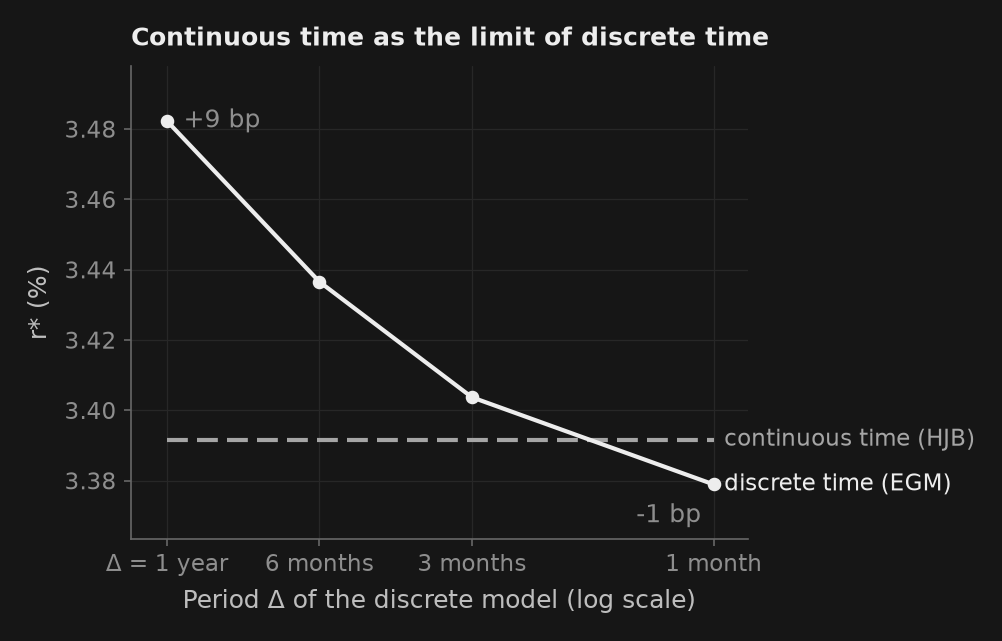

In [14]:
from scipy.linalg import expm, logm

G = logm(P_z).real
print(f"log of the Tauchen chain of §1: smallest off-diagonal rate = {np.min(G - np.diag(np.diag(G))):.4f}  (a generator needs them >= 0)")

rho = -np.log(0.96)                                  # beta = e^{-rho}
Lam = np.array([[-0.2, 0.2], [0.1, -0.1]])           # generator: jumps per year
e_grid = [0.3, 1.0]
malla_ct = np.linspace(0.0, 60.0, 300)
print(f"rho = {rho:.4f};  P = expm(Lam), the one-year transition =\n{np.round(expm(Lam), 4)}")


def continuo():
    m = dp.Model("Aiyagari in continuous time")
    m.parameters(rho=rho, gamma=1.0, alpha=0.36, delta=0.08)
    m.prices(r=(0.005, rho - 0.002))
    m.exogenous("e", dp.Jump(e_grid, Lam))
    m.state("a", malla_ct)                           # the bottom of the grid is the constraint
    m.local("w = (1 - alpha)*(alpha/(r + delta))^(alpha/(1 - alpha))")
    m.control("c")
    m.drift("a", "r*a + w*e - c")                    # da/dt
    m.reward("crra(c, gamma)")
    m.discount_rate("rho")
    m.aggregate(K="a", L="e")
    m.clear("K - L*(alpha/(r + delta))^(1/(1 - alpha))")
    return m


def discreto(Delta, retorno="(1 + r*Delta)"):
    """The twin with period Delta: beta_Delta = e^{-rho Delta}, P_Delta = expm(Lam Delta), a' = R a + w e Delta - c."""
    m = dp.Model("Aiyagari with period Delta")
    m.parameters(beta=float(np.exp(-rho * Delta)), gamma=1.0, alpha=0.36, delta=0.08, Delta=Delta)
    m.prices(r=(0.005, rho - 0.002))
    m.exogenous("e", dp.Markov(e_grid, expm(Lam * Delta)))
    m.state("a", malla_ct)
    m.local("w = (1 - alpha)*(alpha/(r + delta))^(alpha/(1 - alpha))",
            f"c = {retorno}*a + w*e*Delta - a(+1)")   # Delta*u(c/Delta) is u(c) up to a positive factor and a constant, which do not change the policy
    m.reward("crra(c, gamma)")
    m.subject_to("c > 0")
    m.aggregate(K="a", L="e")
    m.clear("K - L*(alpha/(r + delta))^(1/(1 - alpha))")
    return m


t0 = time.perf_counter()
ct = continuo().solve(xtol=1e-8)                     # with drift(), solve() picks "hjb" on its own
t_ct = time.perf_counter() - t0
r_ct, K_ct, g_ct, m0_ct = resumen(ct)
print(f"{'continuous (HJB)':24s} r* = {100 * r_ct:.3f}%  K = {K_ct:.3f}  Gini = {g_ct:.3f}  "
      f"mass at a=0 = {100 * m0_ct:4.1f}%   {t_ct:.1f} s")

periodos = {1: "1 year", 2: "6 months", 4: "3 months", 12: "1 month"}       # periods per year
r_delta = []
for n, nombre in periodos.items():
    t0 = time.perf_counter()
    sd = discreto(1 / n).solve("egm", tol=1e-9, xtol=1e-8)
    r_d, K_d, g_d, m0_d = resumen(sd)
    r_delta.append(r_d)
    print(f"{'discrete, Δ = ' + nombre:24s} r* = {100 * r_d:.3f}%  K = {K_d:.3f}  Gini = {g_d:.3f}  "
          f"mass at a=0 = {100 * m0_d:4.1f}%   {time.perf_counter() - t0:.1f} s")
r_delta = np.array(r_delta)
brecha_pb = 1e4 * (r_delta - r_ct)
r_exacto = discreto(1.0, retorno="exp(r*Delta)").solve("egm", tol=1e-9, xtol=1e-8).prices["r"]   # continuous return over one year
print("discrete - continuous gap in r*: " + ", ".join(f"{b:+.1f} bp with Δ = {nombre}" for b, nombre in zip(brecha_pb, periodos.values()))
      + f"; with Δ = 1 year and the exact return e^(rΔ) instead of 1 + rΔ: {1e4 * (r_exacto - r_ct):+.1f} bp")
assert ct.method == "hjb" and abs(brecha_pb[-1]) < abs(brecha_pb[0]) / 3, "as the period shrinks, the gap to continuous time must fall at least to a third"
assert abs(1e4 * (r_exacto - r_ct)) < abs(brecha_pb[0]) / 2, "with the exact return at least half of the annual gap disappears"

x = np.array(list(periodos))
fig, ax = _nbstyle.figura()
ax.plot(x[[0, -1]], [100 * r_ct] * 2, label="continuous time (HJB)", **_nbstyle.S2)
ax.plot(x, 100 * r_delta, marker="o", label="discrete time (EGM)", **_nbstyle.S1)
ax.annotate(f"{brecha_pb[0]:+.0f} bp", xy=(x[0], 100 * r_delta[0]), xytext=(8, 0), textcoords="offset points",
            ha="left", va="center", color=_nbstyle.NOTA)
ax.annotate(f"{brecha_pb[-1]:+.0f} bp", xy=(x[-1], 100 * r_delta[-1]), xytext=(-6, -9), textcoords="offset points",
            ha="right", va="top", color=_nbstyle.NOTA)
ax.set_xscale("log")                                 # 1, 2, 4 and 12 periods, spread out to the eye
ax.set_xticks(x, ["Δ = " + periodos[1]] + [periodos[n] for n in x[1:]])
ax.xaxis.set_minor_locator(plt.NullLocator())
ax.set_xlim(0.85, 14)
ax.margins(y=0.15)
ax.set_xlabel("Period Δ of the discrete model (log scale)")
ax.set_ylabel("r* (%)")
ax.set_title("Continuous time as the limit of discrete time")
_nbstyle.etiquetar(ax, donde="fin")
plt.show()


**Reading the output.** With a one-year period, the discrete model clears the market $9$ bp above the continuous one ($3.48\,\%$ against $3.39\,\%$; $K$ of $4.57$ against $4.63$). As the period shrinks, the gap falls from $9.1$ bp at one year to $4.5$ at six months and $1.2$ at three: nearly linear in $\Delta$, plus a small spatial offset of the opposite sign that shows at one month. The linear part is the signature of a first-order error in $\Delta$: the budget $a' = a + \Delta\,(ra + we) - c$ is the Euler discretization of $\dot a$. Most of that error is that $(1 + r\Delta)$ is not $e^{r\Delta}$ — over a year, $r^2/2 \approx 6$ bp — and the last line checks it: with the exact return the annual gap drops from $9$ to $3.6$ bp with nothing else touched. With a one-month period $1.3$ bp of the opposite sign remains, and that is no longer the clock: as $\Delta \to 0$ what remains is the difference between two spatial schemes — EGM's lottery across nodes and the HJB's upwind finite differences — which shrinks by refining the grid, not the period (it can be checked by repeating the ladder with a 600-node `malla_ct`). That is the honest comparison: continuous time is not "another model", it is the limit of the discrete one as the period shrinks, and whatever does not vanish in that limit has another cause that must be named.

### 5.4 The Types of §2, Household by Household

`dp` has no "permanent types", and needs none: a type is a household at given prices — the same declaration without `prices()` or `clear()`, with $r^*$ and $w^*$ of §1 as parameters — and the population is the weighted sum of their distributions. That is exactly what `solve_permanent_types` did in §2 under the hood.

In [15]:
def hogar_dp(beta, metodo, malla=a_grid):
    """One type at the prices of §1: the Aiyagari declaration without prices() or clear()."""
    m = dp.Model("household at given prices")
    m.parameters(beta=beta, gamma=1.0, r=r_star, w=w_star)
    m.exogenous("z", dp.AR1(rho=0.9, sigma=0.2, n=5))
    m.state("a", malla)
    m.local("c = w*exp(z) + (1 + r)*a - a(+1)")
    m.reward("crra(c, gamma)")
    m.subject_to("c > 0")
    return m.solve(metodo, tol=1e-9, howard=40)


def reparto(mu):
    """Gini, top 10 % and top 1 % shares, mass at a = 0."""
    pop, val, gini = lorenz_and_gini(mu, wealth_mix)
    return gini, 100 * (1 - np.interp(0.90, pop, val)), 100 * (1 - np.interp(0.99, pop, val)), 100 * mu[0].sum()


print(f"{'SCF mixture, 3 types':26s}{'Gini':>7s}{'top 10%':>10s}{'top 1%':>9s}{'mass at a=0':>13s}")
print(f"{'§2 solve_permanent_types':26s}{gini_mix:7.3f}{top10_mix:9.1f}%{top1_mix:8.1f}%{100 * mu_mix[0].sum():12.1f}%")
for metodo in ("vfi", "egm"):
    t0 = time.perf_counter()
    mu_tipos = sum(peso * hogar_dp(b, metodo).distribution for b, peso in zip(betas_scf, weights_scf))
    t_mezcla = time.perf_counter() - t0
    g, top10, top1, m0 = reparto(mu_tipos)
    print(f"{'dp ' + metodo.upper() + ', mixed by hand':26s}{g:7.3f}{top10:9.1f}%{top1:8.1f}%{m0:12.1f}%   {t_mezcla:.1f} s")
    if metodo == "vfi":
        assert np.array_equal(mu_tipos, mu_mix), "the mixture by hand with VFI is that of §2 bit for bit"
    else:
        assert g > 0.80 and top10 > 60.0, "the SCF calibration of §2 must survive the continuous policy"


SCF mixture, 3 types         Gini   top 10%   top 1%  mass at a=0
§2 solve_permanent_types    0.838     67.4%    11.8%        68.9%


dp VFI, mixed by hand       0.838     67.4%    11.8%        68.9%   0.5 s
dp EGM, mixed by hand       0.818     65.4%    11.4%        52.2%   0.1 s


**Reading the output.** The mixture made by hand with VFI is that of §2 bit for bit: `solve_permanent_types` was nothing more than three problems at given prices and a weighted sum. By EGM the same mixture gives a Gini of $0.82$ and a top $10\,\%$ holding $65\,\%$ of wealth: the SCF calibration survives — still above $0.80$ and $65\,\%$ — but with less slack than §2 suggested, and for the usual reason: with the discrete policy $69\,\%$ of the population lives at the node $a = 0$; with the continuous one, $52\,\%$. Part of the hand-to-mouth households of §2 were grid; a calibrated $\beta$ is a $\beta$ calibrated with a method and a grid, and it is worth saying so.

### Your Turn

The next cell declares the economy of §1 again, with risk aversion and the grid as parameters, and solves it by EGM. The default grid is quadratic — dense near the constraint, where the mass is — with the same 120 nodes as §1, and it lands within 1 bp of the 960-node reference in the table of 5.1: the grid matters more than the method. Change the lines marked `←` and answer:

1. **Basic.** Raise $\gamma$ to $2$ and to $3$. Does the precautionary wedge $(1/\beta - 1) - r^*$ widen? Why does Kimball's prudence predict it? Where do $K$ and the Gini go? With $\gamma = 3$, $r^*$ should fall close to $0.5\,\%$ — check it — the edge of the `prices()` bracket: if `brentq` complains that $r^*$ no longer falls inside it, widen the lower end (to $-0.02$, say) and run again.
2. **Intermediate.** Redo Task 4 of §4 (relaxing credit to $\underline a = -0.5$, at given prices) with `hogar_dp(0.96, metodo, malla=np.linspace(-0.5, 60, 120))` and `.mean("a")` for capital. By VFI you should recover $K = 7.237$ against $7.479$ on the grid of §1 ($+3.3\,\%$, $29.8\,\%$ borrowing). What does EGM give? Which part of Task 4 was grid: the capital amplification or the fraction of borrowers?
3. **Stretch.** Pick one. (a) The same credit relaxation in general equilibrium: `aiyagari_dp(malla=np.linspace(-0.5, 60, 120))` by EGM. How much does $r^*$ rise when households can borrow, and what fraction borrows? (The Gini is undefined with negative wealth; `resumen` returns `nan`.) (b) Embed the chain of §1 in continuous time regardless: clip the negative rates of `logm(P_z)` to zero, recompose the diagonal, measure `max|expm(Λ) − P_z|` and repeat the ladder of Figure 5 with the five states $e = e^{z}$ and the grid of §1. Does it land on the HJB? What changes with a 300-node grid?

In [16]:
GAMMA = 1.0          # ← change this (question 1)
EXPONENTE = 2        # ← or the grid: 1 linear, 2 quadratic, 3 cubic
malla_tu = a_grid[0] + (a_grid[-1] - a_grid[0]) * np.linspace(0, 1, 120) ** EXPONENTE

t0 = time.perf_counter()
tu = aiyagari_dp(gamma=GAMMA, malla=malla_tu).solve("egm", tol=1e-9, xtol=1e-8)
r_tu, K_tu, g_tu, m0_tu = resumen(tu)
cuna_tu = 100 * (1 / 0.96 - 1 - r_tu)
r_fino, K_fino, g_fino, m0_fino = resumen(dp_fino)
print(f"gamma = {GAMMA:g}, {malla_tu.size} nodes (smallest step {np.diff(malla_tu).min():.4f}):  r* = {100 * r_tu:.4f}%  "
      f"precautionary wedge = {cuna_tu:.2f} pp  K = {K_tu:.3f}  Gini = {g_tu:.4f}  mass at a=0 = {100 * m0_tu:.1f}%   {time.perf_counter() - t0:.1f} s")
print(f"fine reference (gamma = 1, EGM, 960 linear nodes):  r* = {100 * r_fino:.4f}%  Gini = {g_fino:.4f}  mass at a=0 = {100 * m0_fino:.1f}%")
assert cuna_tu > 0, "with uninsurable risk, r* stays below 1/beta - 1"
if (GAMMA, EXPONENTE) == (1.0, 2):                   # the check holds for the default values
    assert abs(r_tu - r_fino) < 1e-4 and abs(g_tu - g_fino) < 0.005, "120 quadratic nodes by EGM are within 1 bp and 0.005 of Gini of the fine 960-node grid"


gamma = 1, 120 nodes (smallest step 0.0042):  r* = 3.0779%  precautionary wedge = 1.09 pp  K = 7.465  Gini = 0.6290  mass at a=0 = 9.8%   0.4 s
fine reference (gamma = 1, EGM, 960 linear nodes):  r* = 3.0791%  Gini = 0.6281  mass at a=0 = 10.1%


**How comprehensive is this?** The same declaration takes `horizon(T)` for the life cycle of T06_B — with age-varying parameters, a discrete participation choice and taste shocks, the latter by EGM only — and `aggregate_shock` with `aggregate_state` for the Krusell–Smith of T03_A, where EGM converges in seconds on a grid where the capital simulated by VFI leaves the range and never converges. What `dp` does not do yet, and the notebook keeps doing with `puremacro.vfi`: permanent types (mixed by hand, as in 5.4), two assets by EGM (VFI only), Epstein–Zin, equilibrium with a finite horizon (OLG), more than one price, and panel simulation. From any solution, `summary()` prints the record, and `policy("c")` or `mean("a")` evaluate any expression of the model on the optimal policy.

## Professorial Summary: Incomplete Markets and the Macroeconomics of Wealth

The Bewley-Huggett-Aiyagari framework represents one of the foundational breakthroughs of modern quantitative macroeconomics. By replacing the frictionless representative agent with an explicit cross-sectional distribution of optimizing households subject to uninsurable income shocks and borrowing constraints, it yields five enduring macroeconomic insights:

1. **The Nature of Aggregate Capital and Precautionary Wedges**: Precautionary savings is a first-order general equilibrium macroeconomic force. Because households cannot purchase insurance against unemployment or negative wage shocks, aggregate capital accumulation is systematically higher, and equilibrium interest rates are systematically lower, than the classical Ramsey benchmark ($r^* < 1/\beta - 1$). In economies with high idiosyncratic volatility or underdeveloped social safety nets, the precautionary wedge $\Delta_{\text{prec}}$ widens, permanently depressing the natural rate of interest.
2. **Continuous EGM and Endogenous Borrowing Limits**: The Carroll (2006) Endogenous Grid Method decouples policy inversion from discrete grid search, allowing rapid and continuous policy approximation over hundreds of asset nodes. While the natural borrowing limit $\underline{a}_{\text{nat}} = -w \min(e^z)/r^*$ defines the absolute solvency ceiling, institutional constraints ($a' \ge 0$) generate an active mass of constrained households whose savings policy rules feature sharp kink points.
3. **The Empirical Top-Tail Puzzle and Preference Heterogeneity**: Standard Aiyagari models with homogeneous discount factors predict an exponential upper tail ($\zeta \approx 3.5$) that severely underpredicts empirical wealth concentration (where top 1% wealth exceeds 30% and top 10% exceeds 65%). Incorporating permanent patience heterogeneity ($\beta$-dispersion) matches US Survey of Consumer Finances (SCF) and Federal Reserve DFA targets with high precision ($\text{Gini} \approx 0.84$, top 10% share $> 65\%$, $\zeta \approx 1.92$).
4. **The MPC Distribution Ladder and Stabilization Policy**: Wealth inequality fundamentally alters the monetary and fiscal transmission mechanisms. Households in the bottom quintiles exhibit a high marginal propensity to consume ($MPC_{Q1} \approx 0.91$), behaving as hand-to-mouth consumers. In contrast, wealthy households in top quintiles behave as Ricardian savers with near-zero marginal consumption responses ($MPC_{Q5} \approx 0.04$). Consequently, targeted fiscal transfers injected into the liquidity-poor lower quintiles generate macroeconomic stimulus multipliers far exceeding universal tax rebates.

5. **Declaring versus programming**: the same Bellman equation, written once in the language of the course's `.mod` files, is solved by VFI (which reproduces §1 bit for bit), by EGM (in a fraction of the time, with the market really cleared) and in continuous time (whose $r^*$ is the limit of the discrete one as the period shrinks). Separating the model from the method is what lets one say which part of a result — the mass at $a = 0$, the Gini, a calibration — is economics and which part is grid.